# Perfil e hipótesis del dataset de Deadlock

Ciencia de Datos · UTN FRM · 2026 · Entrega 2

Este notebook responde una sola pregunta: **¿sabemos qué tiene adentro nuestro dataset y podemos defender con un número cada decisión que tomamos sobre él?** Recorre las seis fases del análisis exploratorio (secciones 1 a 6), resuelve cuatro hipótesis en fichas de seis campos (sección 7), y cierra con la tabla de columnas candidatas que se lleva la Entrega 3 (sección 8) y las respuestas para la defensa (sección 9).

Se corre de arriba hacia abajo. Todo lo que se usa acá se calcula acá: los números de las fichas salen de celdas ejecutadas, no están tipeados. Donde una conclusión depende de que un número caiga en cierta zona, hay un `assert` que frena el notebook si los datos cambian y la conclusión deja de valer.

### Qué cambió desde la Entrega 1

Nada: el pipeline y el dataset son los de la Entrega 1, corridos con `fecha_corte = 2026-08-15`.

La pregunta del proyecto **no cambió**: *¿se puede saber quién gana una partida sabiendo solo la composición de héroes de los dos equipos?*

In [66]:
# Las herramientas de todo el notebook
import re, sys, gzip, json, pickle
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

VERDE_AZUL, TERRACOTA = "#009086", "#B5402C"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 120, "display.width", 200)

In [67]:
# Los cortes del semáforo: por debajo del primero es rojo, por encima del segundo es verde
CORTES = {"separacion": (0.2, 0.8), "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}


def semaforo(valor, medida):
    """Devuelve la zona en la que cae el valor, según la medida usada."""
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"


def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)


def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

In [68]:
# Tres ayudas para no confundir un número con una certeza: cuánto se mueve cada medida por puro azar
def error_separacion(d, n1, n2):
    """Error estándar aproximado de una separación estandarizada."""
    return np.sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2)))


def intervalo_correlacion(r, n):
    """Intervalo al 95 % de una correlación, por la transformación de Fisher."""
    z, ee = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * ee), np.tanh(z + 1.96 * ee)


def c(x, d=3):
    """Número con coma decimal, para la prosa en castellano."""
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    """Entero con separador de miles (el § se vuelve punto recién en leer)."""
    return f"{x:,}".replace(",", "§")


def leer(texto):
    """Muestra prosa en castellano: coma decimal fuera de los `códigos`, punto de miles donde hay §."""
    partes = texto.split("`")
    for i in range(0, len(partes), 2):
        partes[i] = re.sub(r"(?<=\d)\.(?=\d)", ",", partes[i])
    display(Markdown("`".join(partes).replace("§", ".")))

In [69]:
# Dónde está el dataset: el CSV más reciente que dejó el DAG
RAIZ = Path.cwd() if (Path.cwd() / "include").exists() else Path.cwd().parent
SALIDA = RAIZ / "include" / "output"
sys.path.insert(0, str(RAIZ / "include"))

ARCHIVO = sorted(SALIDA.glob("deadlock_*.csv"))[-1]
df = pd.read_csv(ARCHIVO)
print("dataset:", ARCHIVO.name)

dataset: deadlock_2026-09-20.csv


In [70]:
# Del CSV al resto de las capas: el corte de la corrida se lee del propio dato, no se tipea
CORTE = df["match_date"].min()
BRONCE, PLATA = SALIDA / "bronze" / f"corte={CORTE}", SALIDA / "silver" / f"corte={CORTE}"
assert BRONCE.exists() and PLATA.exists(), f"no hay bronce/plata para el corte {CORTE}"
base = pd.read_parquet(PLATA / "matches_base.parquet")
gano_A = df["winner"].eq("A")
pd.Series({"corte": CORTE, "filas del CSV": len(df), "filas de matches_base": len(base)})

corte                    2026-08-15
filas del CSV                  9999
filas de matches_base          9999
dtype: object

# Sección 1: Inspección inicial del dataset

### El tamaño y qué es una fila

In [71]:
# ¿Cuántas filas y columnas hay?
df.shape

(9999, 73)

In [72]:
# ¿Qué se ve en una fila típica?
df[["match_id", "match_date", "average_badge", "average_badge_diff", "hero_lash", "hero_seven", "hero_winrate_adv_mean", "winner"]].head()

,match_id,match_date,average_badge,average_badge_diff,hero_lash,hero_seven,hero_winrate_adv_mean,winner
0,99482428,2026-08-15,62,20.833333,0,0,-0.002554,B
1,99482432,2026-08-15,65,0.166667,0,1,0.065055,A
2,99482441,2026-08-15,52,8.500000,1,0,0.003012,B
3,99482447,2026-08-15,13,2.666667,0,-1,0.011639,B
4,99482453,2026-08-15,24,4.166667,0,0,0.044808,A


In [73]:
leer(f"""Una fila es **una partida ranked completa** de Deadlock (`match_id` es su identificador), jugada el {CORTE}. Son {miles(df.shape[0])} filas por {df.shape[1]} columnas, y cada una es un partido de seis contra seis: los héroes de cada equipo están codificados como `+1` (equipo A), `-1` (equipo B) o `0` (no participa).""")

Una fila es **una partida ranked completa** de Deadlock (`match_id` es su identificador), jugada el 2026-08-15. Son 9.999 filas por 73 columnas, y cada una es un partido de seis contra seis: los héroes de cada equipo están codificados como `+1` (equipo A), `-1` (equipo B) o `0` (no participa).

### Los tipos de datos

In [74]:
# ¿Alguna numérica quedó como texto?
df.dtypes.value_counts()

int64      40
float64    29
str         4
Name: count, dtype: int64

In [75]:
# ¿Cuáles son las columnas de texto?
df.select_dtypes(exclude="number").columns.tolist()

['match_date', 'game_mode', 'match_mode', 'winner']

In [76]:
leer(f"""Ninguna numérica quedó como texto. Las {df.select_dtypes(exclude='number').shape[1]} columnas de texto lo son porque **son categorías**: `match_date` (una fecha), `game_mode` y `match_mode` (etiquetas del modo de juego), y `winner` (`A` o `B`, el objetivo).""")

Ninguna numérica quedó como texto. Las 4 columnas de texto lo son porque **son categorías**: `match_date` (una fecha), `game_mode` y `match_mode` (etiquetas del modo de juego), y `winner` (`A` o `B`, el objetivo).

### Setenta y tres columnas en cinco familias

Igual que con cualquier dataset ancho, no se leen de a una: se agrupan. Los prefijos del nombre delatan la familia de cada columna.

In [77]:
# ¿A qué familia pertenece cada columna?
def familia(col):
    if col in ("match_id", "match_date", "game_mode", "match_mode", "average_badge", "average_badge_diff"):
        return "metadatos"
    if col == "winner":
        return "objetivo"
    if col.startswith("hero_winrate"):
        return "hero_winrate (ventaja individual)"
    if col.startswith("hero_"):
        return "composición (un héroe por columna)"
    return "counter y synergy (ventaja en cruces y parejas)"


FAMILIAS = pd.Series({col: familia(col) for col in df.columns})
FAMILIAS.value_counts()

composición (un héroe por columna)                 38
counter y synergy (ventaja en cruces y parejas)    24
metadatos                                           6
hero_winrate (ventaja individual)                   4
objetivo                                            1
Name: count, dtype: int64

Las 38 columnas de composición dicen **quiénes juegan**. Las 28 restantes de ventaja (counter, synergy y hero_winrate) dicen **qué tan bien le fue históricamente a esos héroes**, calculado con partidas de los 14 días *anteriores* a la fecha de corte. Esa separación temporal no es un detalle: es lo que impide que la fila lleve adentro un pedazo de su propia respuesta, y en la sección 5 la ponemos a prueba.

### Las columnas que no varían

In [78]:
# ¿Qué columnas tienen un único valor en todo el dataset?
constantes = df.columns[df.nunique(dropna=False) <= 1].tolist()
df[constantes].iloc[0]

match_date    2026-08-15
game_mode         Normal
match_mode        Ranked
Name: 0, dtype: str

In [79]:
leer(f"""Hay **{len(constantes)} columnas constantes**: {', '.join(f'`{k}`' for k in constantes)}. Ninguna es un error, y las tres tienen causa conocida:

* `game_mode` y `match_mode` son constantes porque **el DAG filtra la descarga** a partidas `normal` y `ranked` (el filtro vive en `include/deadlock/client.py`). Una columna que el propio pipeline fija no puede variar.
* `match_date` es constante porque las partidas se piden con `order_by=match_id` ascendente y `limit=10000`: el cupo se agota antes de que termine el primer día de la ventana. Lo verificamos con el bronce en la sección 5.

Son el equivalente de un nulo estructural: **tienen que estar así**. No informan nada sobre quién gana, y salen del modelo.""")

Hay **3 columnas constantes**: `match_date`, `game_mode`, `match_mode`. Ninguna es un error, y las tres tienen causa conocida:

* `game_mode` y `match_mode` son constantes porque **el DAG filtra la descarga** a partidas `normal` y `ranked` (el filtro vive en `include/deadlock/client.py`). Una columna que el propio pipeline fija no puede variar.
* `match_date` es constante porque las partidas se piden con `order_by=match_id` ascendente y `limit=10000`: el cupo se agota antes de que termine el primer día de la ventana. Lo verificamos con el bronce en la sección 5.

Son el equivalente de un nulo estructural: **tienen que estar así**. No informan nada sobre quién gana, y salen del modelo.

### Los faltantes

In [80]:
# ¿Qué columnas tienen más nulos?
df.isna().mean().sort_values(ascending=False).head(3)

match_id      0.0
match_date    0.0
game_mode     0.0
dtype: float64

In [81]:
# ¿Hay algún nulo en todo el dataset?
int(df.isna().sum().sum())

0

In [82]:
leer(f"""El dataset tiene **{int(df.isna().sum().sum())} nulos**. Eso no es un accidente ni un mérito: el pipeline los previene a propósito. Las columnas de ventaja usan un valor neutro (`0.0`) cuando falta una pareja de héroes en las estadísticas, y el `quality_gate` del DAG frena la corrida si alguna columna queda 100 % nula o si falta algo en las obligatorias. Que no haya nulos no significa que no falte información: significa que **el faltante se resolvió antes de llegar acá**. Si se imputó algo, hay que saber cuánto; lo medimos en la sección 4.""")

El dataset tiene **0 nulos**. Eso no es un accidente ni un mérito: el pipeline los previene a propósito. Las columnas de ventaja usan un valor neutro (`0.0`) cuando falta una pareja de héroes en las estadísticas, y el `quality_gate` del DAG frena la corrida si alguna columna queda 100 % nula o si falta algo en las obligatorias. Que no haya nulos no significa que no falte información: significa que **el faltante se resolvió antes de llegar acá**. Si se imputó algo, hay que saber cuánto; lo medimos en la sección 4.

### La clave

Una fila es una partida, así que la clave natural es `match_id`.

In [83]:
# ¿Se repite algún identificador de partida?
int(df["match_id"].duplicated().sum())

0

### Filas leídas contra filas finales

El bronce trae las partidas tal como las devolvió la API. Entre el bronce y el dataset hay un filtro de calidad (`parse_match`), y lo que ese filtro descarta hay que poder nombrarlo.

In [ ]:
# ¿Cuántas partidas trajo la API y cuántas llegaron al dataset?
paginas = sorted((BRONCE / "matches").glob("pagina_*.json.gz"))
crudas = [m for p in paginas for m in json.load(gzip.open(p, "rt", encoding="utf-8"))]
pd.Series({"partidas en el bronce": len(crudas), "filas en el CSV": len(df), "descartadas": len(crudas) - len(df)})

In [ ]:
# ¿Por qué se descartó?
from deadlock.transform import parse_match

descartadas = [m for m in crudas if parse_match(m) is None]
for m in descartadas:
    print("match_id", m["match_id"], "| jugadores en la partida:", len(m["players"]),
          "| por equipo:", dict(Counter(p["team"] for p in m["players"])))

match_id 99516202 | jugadores en la partida: 11 | por equipo: {'Team1': 5, 'Team0': 6}


In [ ]:
leer(f"""El filtro descartó **{len(descartadas)} partida{'s' if len(descartadas) != 1 else ''}**. No es un dato faltante en el sentido de un nulo: es una partida que no cumple el formato de seis contra seis (`parse_match` exige exactamente 6 héroes válidos por equipo), típicamente por un abandono o un dato parcial. Descartarla es correcto; lo importante es que el descarte está **contado**.""")

El filtro descartó **1 partida**. No es un dato faltante en el sentido de un nulo: es una partida que no cumple el formato de seis contra seis (`parse_match` exige exactamente 6 héroes válidos por equipo), típicamente por un abandono o un dato parcial. Descartarla es correcto; lo importante es que el descarte está **contado**.

# Sección 2: Análisis univariado

### Las medidas de resumen, por familia

Se resume cada familia por separado: mezclar en una misma tabla columnas que valen `±1` con columnas que valen `±3000` no dice nada.

In [ ]:
# ¿Cómo se ven las ventajas de winrate, que son las que dan la señal?
cols_winrate = ["counter_winrate_adv_mean", "synergy_winrate_adv_mean", "hero_winrate_adv_mean"]
df[cols_winrate].describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
counter_winrate_adv_mean,9999.0,0.000,0.032,-0.116,-0.021,0.000,0.022,0.115
synergy_winrate_adv_mean,9999.0,0.001,0.052,-0.184,-0.034,0.001,0.036,0.183
hero_winrate_adv_mean,9999.0,0.001,0.034,-0.124,-0.023,0.000,0.024,0.123


In [ ]:
# ¿Y las que miden souls, kills y muertes?
df[["counter_souls_adv_mean", "counter_kills_adv_mean", "counter_deaths_adv_mean", "counter_assists_adv_mean"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
counter_souls_adv_mean,9999.0,11.48,806.65,-2617.62,-533.46,12.76,560.44,2796.85
counter_kills_adv_mean,9999.0,0.00,0.53,-1.83,-0.36,-0.01,0.36,2.01
counter_deaths_adv_mean,9999.0,-0.01,0.31,-1.28,-0.22,-0.00,0.21,1.20
counter_assists_adv_mean,9999.0,0.01,0.76,-2.63,-0.51,-0.00,0.52,3.16


In [ ]:
# ¿Y las que hablan del nivel de los jugadores?
df[["average_badge", "average_badge_diff"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
average_badge,9999.0,54.31,24.89,11.0,32.00,55.0,76.00,103.00
average_badge_diff,9999.0,0.13,8.27,-48.0,-2.33,0.0,2.83,54.17


In [ ]:
leer(f"""Las tres ventajas de winrate están centradas en 0 (media {c(df['hero_winrate_adv_mean'].mean(), 4)} en `hero_winrate_adv_mean`) y con desvío chico: {c(df['hero_winrate_adv_mean'].std())}. Es lo esperado: son diferencias entre dos equipos, y el equipo A es una etiqueta arbitraria.

Lo que salta a la vista es otra cosa: la escala. `counter_souls_adv_mean` tiene un desvío de **{c(df['counter_souls_adv_mean'].std(), 0)}**, y los winrates de **{c(df['counter_winrate_adv_mean'].std())}**. No es que una sea más variable que la otra: están en unidades distintas (souls contra probabilidad). Cualquier modelo sensible a la magnitud las va a tratar distinto si no se estandarizan antes.

`average_badge_diff` tiene media {c(df['average_badge_diff'].mean(), 2)} y desvío {c(df['average_badge_diff'].std(), 2)}, mientras `average_badge` tiene desvío {c(df['average_badge'].std(), 1)}: **los dos equipos de una misma partida difieren mucho menos entre sí que las partidas entre sí**. Volvemos sobre eso en H4.""")

Las tres ventajas de winrate están centradas en 0 (media 0,0006 en `hero_winrate_adv_mean`) y con desvío chico: 0,034. Es lo esperado: son diferencias entre dos equipos, y el equipo A es una etiqueta arbitraria.

Lo que salta a la vista es otra cosa: la escala. `counter_souls_adv_mean` tiene un desvío de **807**, y los winrates de **0,032**. No es que una sea más variable que la otra: están en unidades distintas (souls contra probabilidad). Cualquier modelo sensible a la magnitud las va a tratar distinto si no se estandarizan antes.

`average_badge_diff` tiene media 0,13 y desvío 8,27, mientras `average_badge` tiene desvío 24,9: **los dos equipos de una misma partida difieren mucho menos entre sí que las partidas entre sí**. Volvemos sobre eso en H4.

### Las medidas de forma

Un histograma por columna sería un catálogo. La pregunta es una sola: ¿alguna numérica tiene cola larga y habría que transformarla?

In [ ]:
# ¿Qué asimetría tienen las numéricas que varían?
variables = df.select_dtypes("number").loc[:, lambda t: t.nunique() > 1]
asimetria = variables.skew().sort_values()
pd.concat([asimetria.head(4), asimetria.tail(4)]).round(2)

counter_assists_adv_max   -0.59
counter_winrate_adv_max   -0.57
counter_deaths_adv_max    -0.54
counter_souls_adv_max     -0.42
counter_souls_adv_min      0.34
counter_winrate_adv_min    0.58
counter_deaths_adv_min     0.58
counter_assists_adv_min    0.61
dtype: float64

In [ ]:
# ¿Cuántas superan el 1 en valor absoluto, que es donde empieza una cola que preocupa?
int((asimetria.abs() > 1).sum())

0

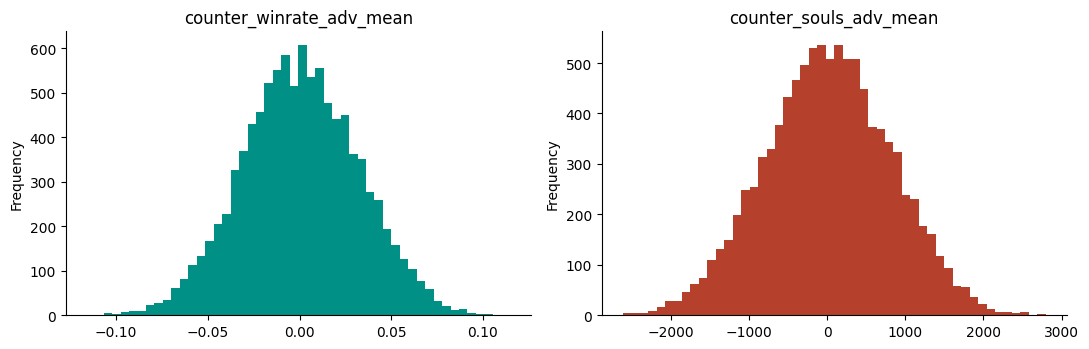

In [ ]:
# ¿Se ve la misma forma en dos columnas de escala tan distinta?
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
for eje, col, color in zip(ejes, ["counter_winrate_adv_mean", "counter_souls_adv_mean"], [VERDE_AZUL, TERRACOTA]):
    df[col].plot.hist(bins=50, ax=eje, color=color, title=col)
plt.tight_layout()
plt.show()

In [ ]:
assert (asimetria.abs() > 1).sum() == 0, "apareció una cola larga: hay que revisar la conclusión de abajo"
leer(f"""**Ninguna numérica tiene cola larga**: la asimetría máxima en valor absoluto es {c(asimetria.abs().max(), 2)}, lejos del 1. No hay nada que llevar a escala logarítmica. Las dos columnas del gráfico tienen **la misma forma** (una campana casi simétrica); lo único que cambia es el eje, de decimales a miles. Eso confirma que `counter_souls_adv_mean` no necesita una transformación sino una **estandarización**.

La razón de fondo de que todo sea tan simétrico está en el pipeline: cada ventaja pasa por un *shrinkage* bayesiano que la centra en 0 y le recorta los extremos que salen de pocas observaciones.""")

**Ninguna numérica tiene cola larga**: la asimetría máxima en valor absoluto es 0,61, lejos del 1. No hay nada que llevar a escala logarítmica. Las dos columnas del gráfico tienen **la misma forma** (una campana casi simétrica); lo único que cambia es el eje, de decimales a miles. Eso confirma que `counter_souls_adv_mean` no necesita una transformación sino una **estandarización**.

La razón de fondo de que todo sea tan simétrico está en el pipeline: cada ventaja pasa por un *shrinkage* bayesiano que la centra en 0 y le recorta los extremos que salen de pocas observaciones.

### El objetivo

Esto es lo más importante de la entrega: la variable a predecir es **`winner`**, y lo primero es ver si una clase se come todo.

In [ ]:
# ¿Qué proporción de partidas gana cada equipo?
df["winner"].value_counts(normalize=True).round(4)

winner
B    0.5019
A    0.4981
Name: proportion, dtype: float64

In [ ]:
# ¿Esa diferencia con el 50 % es más grande de lo que el azar explica?
margen = 1.96 * np.sqrt(0.25 / len(df))
pd.Series({"gana A": gano_A.mean(), "margen de azar (±)": margen, "distancia al 50 %": abs(gano_A.mean() - 0.5)}).round(4)

gana A                0.4981
margen de azar (±)    0.0098
distancia al 50 %     0.0019
dtype: float64

In [ ]:
assert abs(gano_A.mean() - 0.5) < margen
leer(f"""`winner` está **casi perfectamente balanceado**: el equipo A gana el {c(100 * gano_A.mean(), 1)} % de las veces. Con {miles(len(df))} partidas, el azar por sí solo mueve esa proporción hasta ±{c(100 * margen, 1)} puntos, así que la distancia al 50 % ({c(100 * abs(gano_A.mean() - 0.5), 2)} puntos) **no se distingue del azar**.



Esto es un resultado, no una casualidad. Al revés que en un problema de fraude o de abandono, donde una clase domina, acá el equipo A es `Team0` en la API, una asignación **arbitraria respecto de la habilidad**. Un desbalance ahí habría delatado un error en el parseo, no una propiedad del juego.

Consecuencia para la Entrega 3: **la exactitud de la clase mayoritaria es ~50 %**, y ése es el piso contra el que hay que medir cualquier modelo. No hay clase dominante que corregir, pero tampoco hay atajo: un modelo que acierte 60 % ya estaría dando una señal grande.""")

`winner` está **casi perfectamente balanceado**: el equipo A gana el 49,8 % de las veces. Con 9.999 partidas, el azar por sí solo mueve esa proporción hasta ±1,0 puntos, así que la distancia al 50 % (0,19 puntos) **no se distingue del azar**.



Esto es un resultado, no una casualidad. Al revés que en un problema de fraude o de abandono, donde una clase domina, acá el equipo A es `Team0` en la API, una asignación **arbitraria respecto de la habilidad**. Un desbalance ahí habría delatado un error en el parseo, no una propiedad del juego.

Consecuencia para la Entrega 3: **la exactitud de la clase mayoritaria es ~50 %**, y ése es el piso contra el que hay que medir cualquier modelo. No hay clase dominante que corregir, pero tampoco hay atajo: un modelo que acierte 60 % ya estaría dando una señal grande.

### Quiénes se eligen y cuánto ganan

La composición son 38 columnas de héroes. Antes de mirar cuáles importan, hay que ver **cuánto aparece cada uno**, porque un héroe casi ausente da muy poca información.

In [ ]:
# ¿Cuántas partidas juega y cuántas gana cada héroe?
cols_heroe = [k for k in df.columns if k.startswith("hero_") and not k.startswith("hero_winrate")]


def tabla_heroes(datos):
    """Pick rate y winrate de cada héroe en un subconjunto de partidas."""
    gana = datos["winner"].eq("A").astype(int)
    en_A, en_B = datos[cols_heroe].eq(1).astype(int), datos[cols_heroe].eq(-1).astype(int)
    picks = (en_A + en_B).sum()
    victorias = en_A.mul(gana, axis=0).sum() + en_B.mul(1 - gana, axis=0).sum()
    t = pd.DataFrame({"picks": picks, "pickrate": picks / len(datos), "winrate": victorias / picks})
    t.index = t.index.str.replace("hero_", "")
    return t


heroes = tabla_heroes(df)
heroes.sort_values("picks", ascending=False).round(3).iloc[[0, 1, 2, -3, -2, -1]]

,picks,pickrate,winrate
lash,5510,0.551,0.516
bebop,5340,0.534,0.470
infernus,5148,0.515,0.494
silver,1628,0.163,0.485
mirage,1524,0.152,0.444
sinclair,1419,0.142,0.463


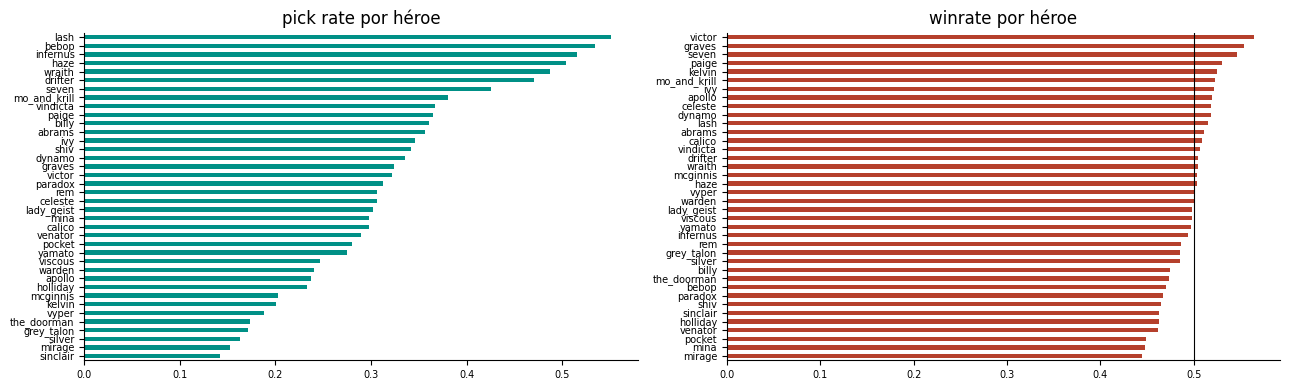

In [ ]:
# ¿Cómo se reparten los picks y los winrates entre los 38 héroes?
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
heroes["pickrate"].sort_values().plot.barh(ax=ejes[0], color=VERDE_AZUL, title="pick rate por héroe", fontsize=7)
heroes["winrate"].sort_values().plot.barh(ax=ejes[1], color=TERRACOTA, title="winrate por héroe", fontsize=7)
ejes[1].axvline(0.5, color="black", lw=.8)
plt.tight_layout()
plt.show()

In [ ]:
mas, menos = heroes["picks"].idxmax(), heroes["picks"].idxmin()
leer(f"""Los picks están **muy desparejos**: `{mas}` aparece en {heroes.loc[mas, 'pickrate']:.0%} de las partidas y `{menos}` en {heroes.loc[menos, 'pickrate']:.0%}, una razón de {heroes['picks'].max() / heroes['picks'].min():.1f} a 1. Los winrates, en cambio, van solo de {heroes['winrate'].min():.1%} a {heroes['winrate'].max():.1%}: ningún héroe rompe el juego. Dos datos para la Entrega 3: los héroes raros tienen pocas filas de las que aprender, y un rango tan chico de winrate anticipa que la señal individual de cada héroe va a ser débil.""")

Los picks están **muy desparejos**: `lash` aparece en 55% de las partidas y `sinclair` en 14%, una razón de 3,9 a 1. Los winrates, en cambio, van solo de 44,4% a 56,4%: ningún héroe rompe el juego. Dos datos para la Entrega 3: los héroes raros tienen pocas filas de las que aprender, y un rango tan chico de winrate anticipa que la señal individual de cada héroe va a ser débil.

# Sección 3: Análisis bivariado

Acá se mira cómo se relacionan las columnas con el objetivo y entre sí. Sin tests estadísticos: con casi diez mil filas casi cualquier diferencia da significativa, y lo que importa es **si es lo bastante grande como para cambiar una decisión**. Por eso las medidas de esta cátedra son tamaños de efecto, con un semáforo que se define más abajo.

### La ventaja teórica contra quién gana

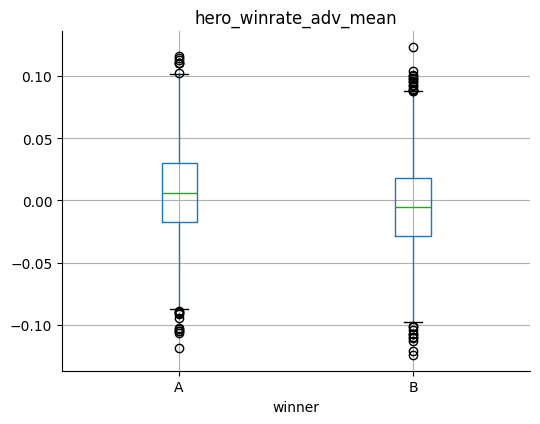

In [ ]:
# ¿Los equipos que ganan tenían una ventaja teórica distinta?
df.boxplot(column="hero_winrate_adv_mean", by="winner", figsize=(5.5, 4.5))
plt.suptitle("")
plt.tight_layout()
plt.show()

Las dos cajas están corridas, y también se superponen mucho. Hay señal, pero no separa limpio. Cuánta es y qué zona le corresponde es la **primera hipótesis** (H1). Por ahora, esa superposición fija la expectativa: ningún modelo basado solo en esto va a acertar todo.

### Las columnas de ventaja entre sí

Son 28 columnas que salen de las mismas tres tablas de estadísticas. La pregunta bivariada no es contra el objetivo sino **entre ellas**: si dos miden lo mismo, una sobra.

In [ ]:
# ¿Qué tanto se parecen entre sí las tres ventajas de winrate y las otras diferencias?
resumen = ["hero_winrate_adv_mean", "counter_winrate_adv_mean", "synergy_winrate_adv_mean",
           "counter_souls_adv_mean", "counter_assists_adv_mean", "counter_kills_adv_mean"]
df[resumen].corr().round(3).style.background_gradient(cmap="RdBu", vmin=-1, vmax=1)

,hero_winrate_adv_mean,counter_winrate_adv_mean,synergy_winrate_adv_mean,counter_souls_adv_mean,counter_assists_adv_mean,counter_kills_adv_mean
hero_winrate_adv_mean,1.000000,0.998000,0.988000,0.499000,0.476000,0.060000
counter_winrate_adv_mean,0.998000,1.000000,0.988000,0.497000,0.482000,0.058000
synergy_winrate_adv_mean,0.988000,0.988000,1.000000,0.485000,0.485000,0.040000
counter_souls_adv_mean,0.499000,0.497000,0.485000,1.000000,0.098000,-0.027000
counter_assists_adv_mean,0.476000,0.482000,0.485000,0.098000,1.000000,-0.214000
counter_kills_adv_mean,0.060000,0.058000,0.040000,-0.027000,-0.214000,1.000000


Tres columnas dan correlaciones cercanas a 1 entre sí, y las otras tres quedan lejos de ellas. Eso es una **segunda pregunta abierta** (H3). El hecho de que una relación sea fuerte no dice que sea trivial: hay que entender *por qué* lo es antes de borrar nada.

### Los héroes contra quién gana

La composición son 38 columnas de `±1/0`. ¿Alguna, por sí sola, tiene una relación fuerte con el resultado?

In [ ]:
# ¿Qué tan separados quedan los equipos ganadores y perdedores según cada héroe?
sep_heroe = pd.Series({k: separacion(df.loc[gano_A, k], df.loc[~gano_A, k]) for k in cols_heroe})
sep_heroe.index = sep_heroe.index.str.replace("hero_", "")
sep_heroe.sort_values(ascending=False).round(3).iloc[[0, 1, 2, -3, -2, -1]]

victor     0.146
graves     0.123
seven      0.120
viscous    0.004
vyper      0.003
warden     0.000
dtype: float64

In [ ]:
zonas = sep_heroe.map(lambda v: semaforo(v, "separacion")).value_counts()
leer(f"""El héroe más informativo por sí solo es `{sep_heroe.idxmax()}`, con una separación de **{c(sep_heroe.max())}**, y el menos, `{sep_heroe.idxmin()}`, con {c(sep_heroe.min())}. Con el semáforo de separación (rojo por debajo de 0,2), **{zonas.get('rojo', 0)} de los 38 héroes caen en rojo**. Ningún héroe aislado decide una partida, y eso es coherente con un juego donde el resultado depende de *cómo se combinan* seis héroes contra otros seis.""")

El héroe más informativo por sí solo es `victor`, con una separación de **0,146**, y el menos, `warden`, con 0,000. Con el semáforo de separación (rojo por debajo de 0,2), **38 de los 38 héroes caen en rojo**. Ningún héroe aislado decide una partida, y eso es coherente con un juego donde el resultado depende de *cómo se combinan* seis héroes contra otros seis.

# Sección 4: Análisis de calidad de datos

### Los valores que faltan en silencio

El profe de la cátedra muestra que un `0` puede ser un faltante disfrazado. Acá el candidato es el **valor neutro `0.0`** que el pipeline pone cuando una pareja de héroes no aparece en las estadísticas: parece una ventaja nula, pero en realidad es un dato que falta. ¿Cuántas filas cargan con eso?

In [ ]:
# ¿Cuántas partidas tienen algún cruce o alguna pareja que no estaba en las estadísticas?
from itertools import combinations
from deadlock import schema

tablas = pickle.load(open(PLATA / "stat_tables.pkl", "rb"))
id_de = {"hero_" + slug: hid for hid, slug in schema.HEROES}
ids = [id_de[k] for k in cols_heroe]


def con_dato_faltante(fila):
    a = [ids[i] for i in np.where(fila == 1)[0]]
    b = [ids[i] for i in np.where(fila == -1)[0]]
    sin_cruce = any((x, y) not in tablas["counter"] for x in a for y in b)
    sin_pareja = any(frozenset(p) not in tablas["synergy"] for p in list(combinations(a, 2)) + list(combinations(b, 2)))
    return sin_cruce or sin_pareja


faltantes_ocultos = int(np.apply_along_axis(con_dato_faltante, 1, df[cols_heroe].to_numpy()).sum())
pd.Series({"cruces en la tabla counter": len(tablas["counter"]), "parejas en la tabla synergy": len(tablas["synergy"]),
           "partidas con algún dato imputado": faltantes_ocultos})

cruces en la tabla counter          1408
parejas en la tabla synergy          703
partidas con algún dato imputado       0
dtype: int64

In [ ]:
leer(f"""**{faltantes_ocultos} partidas** cargan con un valor neutro imputado. El camino del `0.0` existe en el código (`_counter_adv` y `_synergy_adv` en `transform.py`) pero **nunca se dispara**: la tabla de counters cubre {len(tablas['counter'])} cruces y la de synergy las {len(tablas['synergy'])} parejas posibles entre 38 héroes, porque se pidió con `min_matches = 1` para no perder ninguna. Es una imputación que existe como red de seguridad y que en esta corrida no se usó; no hay un cero escondido que interpretar.""")

**0 partidas** cargan con un valor neutro imputado. El camino del `0.0` existe en el código (`_counter_adv` y `_synergy_adv` en `transform.py`) pero **nunca se dispara**: la tabla de counters cubre 1408 cruces y la de synergy las 703 parejas posibles entre 38 héroes, porque se pidió con `min_matches = 1` para no perder ninguna. Es una imputación que existe como red de seguridad y que en esta corrida no se usó; no hay un cero escondido que interpretar.

### Los duplicados y la elección de la clave

Antes de contar duplicados hay que decidir qué cuenta como *la misma fila*.

In [ ]:
# ¿Hay duplicados según tres definiciones distintas de "la misma fila"?
pd.Series({"misma partida (match_id)": int(df.duplicated(subset=["match_id"]).sum()),
           "fila completa": int(df.duplicated().sum()),
           "misma composición de héroes": int(df.duplicated(subset=cols_heroe).sum())})

misma partida (match_id)       0
fila completa                  0
misma composición de héroes    0
dtype: int64

Las tres dan cero. La tercera importa por una razón concreta: si dos partidas distintas tuvieran exactamente los mismos doce héroes en los mismos equipos, **no serían duplicados** (son dos partidas reales) pero sí tendrían la misma fila de composición, y el modelo vería la misma entrada con salidas posiblemente distintas. Acá no pasa: con 38 héroes repartidos de a seis por equipo hay millones de composiciones posibles, y diez mil partidas no se repiten.

### La consistencia interna

In [ ]:
# ¿Todas las filas tienen 6 héroes por equipo, y los mismos héroes no están en los dos equipos?
comp = df[cols_heroe]
pd.Series({"filas con exactamente 6 en A": int(comp.eq(1).sum(axis=1).eq(6).sum()),
           "filas con exactamente 6 en B": int(comp.eq(-1).sum(axis=1).eq(6).sum()),
           "filas totales": len(df)})

filas con exactamente 6 en A    9999
filas con exactamente 6 en B    9999
filas totales                   9999
dtype: int64

In [ ]:
# ¿Los textos tienen una sola forma de escribirse?
df[["game_mode", "match_mode", "winner"]].apply(lambda s: s.unique().tolist())

game_mode     [Normal]
match_mode    [Ranked]
winner          [B, A]
dtype: object

Todas las filas tienen los seis héroes por equipo y no hay ninguna categoría escrita de dos maneras. La integridad estructural está bien.

### La columna que hay que mirar con más cuidado: `average_badge_diff`

`average_badge_diff` se construye con el **rango inicial de cada jugador** (`player_rank_initial_display_rank`), promediado por equipo. Antes de usarla conviene mirar cómo está codificado ese rango, porque de eso depende cuánto vale el promedio.

In [ ]:
# ¿Qué valores toma el rango inicial de un jugador?
rangos = pd.DataFrame([(p["player_rank_initial_display_rank"], p["player_rank_initial_calibration_games"])
                       for m in crudas for p in m["players"]], columns=["rango", "partidas_de_calibracion"])
pd.Series({"jugadores": len(rangos), "con rango 0": int((rangos["rango"] == 0).sum()),
           "subrangos distintos de 0": sorted((rangos.loc[rangos["rango"] > 0, "rango"] % 10).unique().tolist())})

jugadores                               119999
con rango 0                              12775
subrangos distintos de 0    [1, 2, 3, 4, 5, 6]
dtype: object

In [ ]:
# ¿Quiénes son los que tienen rango 0?
rangos.groupby(rangos["rango"] == 0)["partidas_de_calibracion"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
rango,,,,,,,,
False,107224.0,0.0,0.1,0.0,0.0,0.0,0.0,1.0
True,12775.0,5.0,2.0,2.0,3.0,5.0,7.0,8.0


In [ ]:
con_calibrando = sum(any(p["player_rank_initial_display_rank"] == 0 for p in m["players"]) for m in crudas)
leer(f"""Dos hallazgos sobre la codificación, y los dos afectan cómo se lee la columna:

1. **El rango 0 no es "el peor rango": son jugadores en calibración.** El {(rangos['rango'] == 0).mean():.1%} de los jugadores tiene rango 0 y todos ellos tienen partidas de calibración pendientes (mediana {rangos.loc[rangos['rango'] == 0, 'partidas_de_calibracion'].median():.0f}), mientras que los demás casi no tienen. Aún no tienen rango. Pero el pipeline los promedia como si valieran 0, y **el {con_calibrando / len(crudas):.0%} de las partidas tiene al menos uno**. Es un valor faltante escrito como cero, el mismo problema que el profe muestra con los `value_eur = 0`, con la diferencia de que acá no se ve porque queda mezclado dentro de un promedio.
2. **Los subrangos van de 1 a 6**, y el rango es `tier*10 + subrank`. Entre `tier 3, subrank 6` (36) y `tier 4, subrank 1` (41) hay un salto de 5 en el número, pero de un solo escalón en el juego. **El promedio de esos números no es una escala lineal.**

Ninguna de las dos cosas invalida la columna, pero **las dos son razones para desconfiar de una conclusión que dependa de ella**. La refutación de H4 tiene que pasar una prueba de robustez con el rango linealizado y sin los jugadores en calibración; la hacemos ahí.""")

Dos hallazgos sobre la codificación, y los dos afectan cómo se lee la columna:

1. **El rango 0 no es "el peor rango": son jugadores en calibración.** El 10,6% de los jugadores tiene rango 0 y todos ellos tienen partidas de calibración pendientes (mediana 5), mientras que los demás casi no tienen. Aún no tienen rango. Pero el pipeline los promedia como si valieran 0, y **el 65% de las partidas tiene al menos uno**. Es un valor faltante escrito como cero, el mismo problema que el profe muestra con los `value_eur = 0`, con la diferencia de que acá no se ve porque queda mezclado dentro de un promedio.
2. **Los subrangos van de 1 a 6**, y el rango es `tier*10 + subrank`. Entre `tier 3, subrank 6` (36) y `tier 4, subrank 1` (41) hay un salto de 5 en el número, pero de un solo escalón en el juego. **El promedio de esos números no es una escala lineal.**

Ninguna de las dos cosas invalida la columna, pero **las dos son razones para desconfiar de una conclusión que dependa de ella**. La refutación de H4 tiene que pasar una prueba de robustez con el rango linealizado y sin los jugadores en calibración; la hacemos ahí.

# Sección 5: Análisis temporal y validación anti-fuga

### Un dataset de un solo día

In [ ]:
# ¿Qué período cubren en realidad las partidas?
horas = pd.to_datetime([m["start_time"] for m in crudas])
pd.Series({"primera partida": horas.min(), "última partida": horas.max(), "horas cubiertas": round((horas.max() - horas.min()).total_seconds() / 3600, 1)})

primera partida    2026-08-15 00:00:00
última partida     2026-08-15 15:44:26
horas cubiertas                   15.7
dtype: object

In [ ]:
leer(f"""Las {miles(len(crudas))} partidas ocupan **{c((horas.max() - horas.min()).total_seconds() / 3600, 1)} horas de un mismo día**: `match_date` es una sola fecha porque el pedido usa `order_by=match_id` ascendente con tope de 10§000, y el cupo se agota antes de que termine el día, aunque la ventana de partidas del DAG abarca varios días. Consecuencia: **no hay serie temporal que analizar** y `match_date` no puede ser feature ni servir de partición temporal. Un análisis de tendencia o estacionalidad acá sería inventar estructura que el dato no tiene.""")

Las 10.000 partidas ocupan **15,7 horas de un mismo día**: `match_date` es una sola fecha porque el pedido usa `order_by=match_id` ascendente con tope de 10.000, y el cupo se agota antes de que termine el día, aunque la ventana de partidas del DAG abarca varios días. Consecuencia: **no hay serie temporal que analizar** y `match_date` no puede ser feature ni servir de partición temporal. Un análisis de tendencia o estacionalidad acá sería inventar estructura que el dato no tiene.

### El chequeo de que las dos ventanas no se pisan

El pipeline separa las estadísticas históricas (los 14 días *anteriores* al corte `T`) de las partidas que son filas (todo lo *posterior* a `T`). Si se pisaran, la fila llevaría adentro un pedazo de su propia respuesta.

In [ ]:
# ¿La primera partida es posterior al corte, como exige el diseño?
T = pd.Timestamp(CORTE)
pd.Series({"corte T": T, "primera partida": horas.min(), "¿no anterior a T?": bool(horas.min() >= T)})

corte T              2026-08-15 00:00:00
primera partida      2026-08-15 00:00:00
¿no anterior a T?                   True
dtype: object

Se cumple, y con igualdad exacta: la primera partida es del segundo cero del corte. Eso significa que las ventanas se tocan en el borde sin superponerse. Es correcto, pero es un **borde y no un margen**: cualquier partida que la API hubiera etiquetado un segundo antes se habría colado en las dos ventanas.

### ¿Sirvió de algo separar las ventanas? Un experimento contrafáctico

Verificar que las ventanas no se pisan es un argumento. Lo que vale es un número: **cuánto habría inflado el resultado un pipeline que sí las pisara**. Para medirlo hay que construir a propósito la versión con fuga: calcular las tablas de estadísticas con las mismas partidas que después se evalúan.

In [ ]:
# Las dos funciones que arman las ventajas, con y sin fuga
from deadlock.shrink import shrink_rate


def tablas_de(partidas, k):
    """Winrate de cada héroe y de cada cruce, calculados sobre las partidas dadas, con shrinkage k."""
    gana_h, n_h, gana_c, n_c = Counter(), Counter(), Counter(), Counter()
    for a, b, gA in zip(partidas["heroes_a"], partidas["heroes_b"], partidas["winner"].eq("A")):
        gA = int(gA)
        for h in a:
            n_h[h] += 1; gana_h[h] += gA
        for h in b:
            n_h[h] += 1; gana_h[h] += 1 - gA
        for x in a:
            for y in b:
                n_c[x, y] += 1; gana_c[x, y] += gA
                n_c[y, x] += 1; gana_c[y, x] += 1 - gA
    hero = {h: shrink_rate(gana_h[h], n_h[h], k) for h in n_h}
    cruce = {p: shrink_rate(gana_c[p], n_c[p], k) for p in n_c}
    return hero, cruce


def ventajas(partidas, hero, cruce):
    """Las dos ventajas de winrate de cada partida, buscadas en las tablas dadas."""
    vh = [np.mean([hero.get(x, 0) for x in a]) - np.mean([hero.get(y, 0) for y in b])
          for a, b in zip(partidas["heroes_a"], partidas["heroes_b"])]
    vc = [np.mean([cruce.get((x, y), 0) for x in a for y in b]) for a, b in zip(partidas["heroes_a"], partidas["heroes_b"])]
    return pd.DataFrame({"hero": vh, "counter": vc}, index=partidas.index)

In [ ]:
# ¿Qué separación da cada ventaja cuando las tablas se calculan con las mismas partidas que se evalúan?
K = 1000
v_fuga = ventajas(base, *tablas_de(base, K))
gA_base = base["winner"].eq("A")
d_fuga = {col: separacion(v_fuga.loc[gA_base, col], v_fuga.loc[~gA_base, col]) for col in v_fuga}
d_limpio = {"hero": separacion(df.loc[gano_A, "hero_winrate_adv_mean"], df.loc[~gano_A, "hero_winrate_adv_mean"]),
            "counter": separacion(df.loc[gano_A, "counter_winrate_adv_mean"], df.loc[~gano_A, "counter_winrate_adv_mean"])}
pd.DataFrame({"limpio (ventana previa)": d_limpio, "con fuga": d_fuga}).assign(
    inflacion=lambda t: (t["con fuga"] / t["limpio (ventana previa)"] - 1)).round(3)

,limpio (ventana previa),con fuga,inflacion
hero,0.348,0.381,0.096
counter,0.351,0.448,0.275


Con fuga, las dos ventajas se ven **más informativas de lo que realmente son**, y el inflado es mucho mayor en los cruces que en el winrate individual. La explicación es de tamaño de muestra: cada héroe aparece en miles de partidas y la suya propia pesa una parte diminuta de su winrate; cada *cruce* (héroe contra héroe) aparece en unos cientos, y ahí una sola partida pesa varias veces más.

Pero este experimento mezcla dos cosas: la fuga y el hecho de que las tablas con fuga se armaron con **solo 9.999 partidas**, en vez de con las millones de la ventana de 14 días. Un tamaño de muestra chico infla la señal por sí solo, con o sin fuga. Falta un control que aísle la fuga.

### El control: mismo tamaño, sin fuga

Se parte el dataset en dos mitades disjuntas (por paridad de `match_id`). Las tablas armadas con una mitad y evaluadas en la **otra** tienen el mismo tamaño chico pero ninguna fuga. Compararlas con las tablas armadas y evaluadas en la **misma** mitad aísla lo que es fuga pura.

In [ ]:
# ¿Cuánto de la inflación es fuga y cuánto es solo tener pocas partidas?
P, Q = base[base["match_id"] % 2 == 0], base[base["match_id"] % 2 == 1]
gQ = Q["winner"].eq("A")
v_sin = ventajas(Q, *tablas_de(P, K))      # tablas de una mitad, evaluadas en la otra
v_con = ventajas(Q, *tablas_de(Q, K))      # tablas de una mitad, evaluadas en esa misma mitad
control = pd.DataFrame({"mitad distinta (sin fuga)": {k: separacion(v_sin.loc[gQ, k], v_sin.loc[~gQ, k]) for k in v_sin},
                        "misma mitad (con fuga)": {k: separacion(v_con.loc[gQ, k], v_con.loc[~gQ, k]) for k in v_con}})
control.assign(fuga_pura=lambda t: t["misma mitad (con fuga)"] / t["mitad distinta (sin fuga)"] - 1).round(3)

,mitad distinta (sin fuga),misma mitad (con fuga),fuga_pura
hero,0.348,0.397,0.140
counter,0.337,0.517,0.535


In [ ]:
fuga_hero = d_fuga["hero"] / d_limpio["hero"] - 1
fuga_cruce = d_fuga["counter"] / d_limpio["counter"] - 1
pura = control["misma mitad (con fuga)"] / control["mitad distinta (sin fuga)"] - 1
assert fuga_cruce > fuga_hero and pura["counter"] > pura["hero"], "la conclusión sobre cruces vs winrate individual dejó de valer"
partidas_ventana = pd.DataFrame(json.load(open(BRONCE / "stats" / "hero_stats.json")))["matches"].sum() / 12
leer(f"""**Resultado del contrafáctico.** Contra la ventana previa (la real), una tabla con fuga infla la separación del winrate individual un **{fuga_hero:.1%}** y la de los cruces un **{fuga_cruce:.1%}**. Con el control de mismo tamaño, la fuga *pura* infla el winrate individual un **{pura['hero']:.1%}** y los cruces un **{pura['counter']:.1%}**.

Tres lecturas, de la más firme a la más matizada:

1. **Los cruces son los más expuestos.** En las dos mediciones la fuga pesa bastante más sobre los cruces que sobre el winrate individual. Cada héroe aparece en miles de partidas y una sola pesa poco; cada cruce (héroe contra héroe) aparece en cientos.
2. **El número es una cota superior, no una estimación de lo que pasaría en el pipeline.** El experimento arma las tablas con solo {miles(len(base))} partidas. Las estadísticas reales usan unas {miles(int(partidas_ventana))} de la ventana de 14 días, así que si las ventanas se pisaran, las partidas propias pesarían un {len(base) / partidas_ventana:.1%} de la tabla y no el 100 %. El inflado real sería bastante menor, y más para los cruces raros que para los frecuentes.
3. **Por eso separar las ventanas es la decisión correcta aunque el riesgo medido sea moderado**: elimina el problema en vez de tener que estimarlo. Esto responde a *«¿qué columna descartaste por fuga?»*: **ninguna**, porque la fuga en este dataset no vive en una columna sino en **la ventana temporal con la que se calculó cada columna**, y esa ventana está bien.""")

**Resultado del contrafáctico.** Contra la ventana previa (la real), una tabla con fuga infla la separación del winrate individual un **9,6%** y la de los cruces un **27,5%**. Con el control de mismo tamaño, la fuga *pura* infla el winrate individual un **14,0%** y los cruces un **53,5%**.

Tres lecturas, de la más firme a la más matizada:

1. **Los cruces son los más expuestos.** En las dos mediciones la fuga pesa bastante más sobre los cruces que sobre el winrate individual. Cada héroe aparece en miles de partidas y una sola pesa poco; cada cruce (héroe contra héroe) aparece en cientos.
2. **El número es una cota superior, no una estimación de lo que pasaría en el pipeline.** El experimento arma las tablas con solo 9.999 partidas. Las estadísticas reales usan unas 291.073 de la ventana de 14 días, así que si las ventanas se pisaran, las partidas propias pesarían un 3,4% de la tabla y no el 100 %. El inflado real sería bastante menor, y más para los cruces raros que para los frecuentes.
3. **Por eso separar las ventanas es la decisión correcta aunque el riesgo medido sea moderado**: elimina el problema en vez de tener que estimarlo. Esto responde a *«¿qué columna descartaste por fuga?»*: **ninguna**, porque la fuga en este dataset no vive en una columna sino en **la ventana temporal con la que se calculó cada columna**, y esa ventana está bien.

### ¿Cuánto importa el `k` del shrinkage?

El *shrinkage* `k` es el peso de una "previa" de 50 % de winrate: `shrink_rate(wins, n, k) = 2·((wins + k/2)/(n + k)) − 1`. Cuanto mayor es `k`, más se acercan a 0 las ventajas que salen de pocas observaciones. Antes de justificar la elección, hay que comprobar con qué `k` se generó el CSV.

In [ ]:
# ¿Con qué k se calculó realmente la columna hero_winrate_adv_mean del CSV?
hs = pd.DataFrame(json.load(open(BRONCE / "stats" / "hero_stats.json")))
cs = pd.DataFrame(json.load(open(BRONCE / "stats" / "counter_stats.json")))
alineado = base.merge(df[["match_id", "hero_winrate_adv_mean", "counter_winrate_adv_mean"]], on="match_id")
gA_al = alineado["winner"].eq("A")

filas = []
for k in [1, 10, 100, 1000, 10000]:
    hero = {r.hero_id: shrink_rate(r.wins, r.matches, k) for r in hs.itertuples()}
    cruce = {(r.hero_id, r.enemy_hero_id): shrink_rate(r.wins, r.matches_played, k) for r in cs.itertuples()}
    v = ventajas(alineado, hero, cruce)
    filas.append({"k": k,
                  "diferencia máxima con el CSV (hero)": (v["hero"] - alineado["hero_winrate_adv_mean"]).abs().max(),
                  "separación hero": separacion(v.loc[gA_al, "hero"], v.loc[~gA_al, "hero"]),
                  "separación counter": separacion(v.loc[gA_al, "counter"], v.loc[~gA_al, "counter"])})
sensibilidad_k = pd.DataFrame(filas).set_index("k")
sensibilidad_k.round(4)

,diferencia máxima con el CSV (hero),separación hero,separación counter
k,,,
1,0.0017,0.3475,0.3515
10,0.0017,0.3475,0.3515
100,0.0015,0.3475,0.3514
1000,0.0000,0.3475,0.3512
10000,0.0131,0.3472,0.3456


In [ ]:
k_usado = sensibilidad_k["diferencia máxima con el CSV (hero)"].idxmin()
soporte = cs["matches_played"]
assert k_usado == 1000, f"el CSV no se generó con k=1000 sino con k={k_usado}"
leer(f"""**El CSV se generó con `k = {k_usado}`**: es el único valor para el que la diferencia máxima con la columna del CSV es prácticamente cero ({sensibilidad_k.loc[k_usado].iloc[0]:.1e}).

Y ahora la pregunta de fondo: ¿importa? La separación va de {c(sensibilidad_k['separación hero'].min())} a {c(sensibilidad_k['separación hero'].max())} para el winrate individual y de {c(sensibilidad_k['separación counter'].min())} a {c(sensibilidad_k['separación counter'].max())} para los cruces, cuando `k` recorre cuatro órdenes de magnitud. La razón es que **casi ningún cruce tiene pocas observaciones**: la mediana es de {miles(int(soporte.median()))} partidas por cruce, y solo el {(soporte < 1000).mean():.1%} de los cruces tiene menos de 1§000, que es donde `k = 1000` empieza a recortar de verdad. Un `k` alto protege a esos pocos cruces raros sin tocar al resto; por eso `1000` es una elección segura, no una elección que haya cambiado el resultado.""")

**El CSV se generó con `k = 1000`**: es el único valor para el que la diferencia máxima con la columna del CSV es prácticamente cero (1,0e-16).

Y ahora la pregunta de fondo: ¿importa? La separación va de 0,347 a 0,348 para el winrate individual y de 0,346 a 0,351 para los cruces, cuando `k` recorre cuatro órdenes de magnitud. La razón es que **casi ningún cruce tiene pocas observaciones**: la mediana es de 12.510 partidas por cruce, y solo el 0,1% de los cruces tiene menos de 1.000, que es donde `k = 1000` empieza a recortar de verdad. Un `k` alto protege a esos pocos cruces raros sin tocar al resto; por eso `1000` es una elección segura, no una elección que haya cambiado el resultado.

Ésta es la respuesta honesta a *«¿por qué k = 1000?»*: **variarlo casi no mueve las separaciones**, así que no es una decisión de la que dependa la señal. Se eligió por prudencia con los cruces raros, y el número de arriba muestra cuánto cuesta esa prudencia: prácticamente nada.

# Sección 6: De la exploración a las hipótesis

### Lo que el recorrido dejó en claro

In [ ]:
leer(f"""1. **Una fila es una partida ranked completa**, y hay {miles(len(df))} de {miles(len(crudas))} leídas: el filtro de seis contra seis descartó {len(descartadas)}.
2. **`winner` está balanceado**: A gana el {c(100 * gano_A.mean(), 1)} %. El piso de exactitud es ~50 %, sin clase dominante.
3. **Hay {len(constantes)} columnas constantes** ({', '.join(f'`{k}`' for k in constantes)}), todas estructurales.
4. **Cero nulos**, y también cero imputaciones: {faltantes_ocultos} partidas cargan con un valor neutro.
5. **Ninguna numérica tiene cola larga** (asimetría máxima {c(asimetria.abs().max(), 2)}), pero las escalas difieren en cuatro órdenes de magnitud.
6. **Ningún héroe aislado separa a los equipos** ({zonas.get('rojo', 0)} de 38 en rojo); la señal está en las columnas de ventaja.
7. **La separación de ventanas elimina un riesgo medible**: con las tablas armadas sobre las mismas partidas, los cruces se inflarían hasta un {fuga_cruce:.0%} (cota superior).""")

1. **Una fila es una partida ranked completa**, y hay 9.999 de 10.000 leídas: el filtro de seis contra seis descartó 1.
2. **`winner` está balanceado**: A gana el 49,8 %. El piso de exactitud es ~50 %, sin clase dominante.
3. **Hay 3 columnas constantes** (`match_date`, `game_mode`, `match_mode`), todas estructurales.
4. **Cero nulos**, y también cero imputaciones: 0 partidas cargan con un valor neutro.
5. **Ninguna numérica tiene cola larga** (asimetría máxima 0,61), pero las escalas difieren en cuatro órdenes de magnitud.
6. **Ningún héroe aislado separa a los equipos** (38 de 38 en rojo); la señal está en las columnas de ventaja.
7. **La separación de ventanas elimina un riesgo medible**: con las tablas armadas sobre las mismas partidas, los cruces se inflarían hasta un 28% (cota superior).

### Las preguntas que quedaron abiertas

* **¿Cuánta señal hay de verdad en la ventaja teórica?** El boxplot muestra dos cajas corridas y superpuestas. Se convierte en **H1**.
* **¿Los héroes más elegidos son los que más ganan?** Los picks están muy desparejos y los winrates muy parejos; si la comunidad elige bien, deberían moverse juntos. Se convierte en **H2**.
* **¿Las tres ventajas de winrate miden lo mismo?** La matriz de correlación las muestra pegadas. Se convierte en **H3**.
* **¿El equipo con mejor rango gana?** `average_badge_diff` resume el rango previo de cada equipo; falta saber si aporta algo. Se convierte en **H4**.

### Lo que sigue

Cuatro hipótesis, con la regla del orden: en cada una la afirmación y lo que esperamos ver están **escritos antes** de correr la medida. Dos responden algo sobre el dominio del juego (H1 y H2) y dos deciden sobre una columna del modelo (H3 y H4).

# Sección 7: Las cuatro hipótesis

### El semáforo, con los cortes de la cátedra

| Medida | Rojo | Amarillo | Verde |
|---|---|---|---|
| separación (Cohen) | < 0,2 | 0,2 – 0,8 | > 0,8 |
| correlación (Pearson / Spearman) | < 0,2 | 0,2 – 0,6 | > 0,6 |
| brecha (Spearman − Pearson) | < 0,05 | 0,05 – 0,15 | > 0,15 |

Verde y rojo **terminan** la hipótesis. Amarillo habilita un movimiento (partir la población, controlar una tercera variable o cambiar la escala), elegido mirando el gráfico, con un tope de **dos**. Si tras el segundo sigue amarillo, la conclusión es *inconclusa*.

Cada ficha lleva los seis campos: **afirmación**, **qué espero ver**, **medida y gráfico**, **resultado con su zona**, **movimiento** (si hubo), y **qué hago con eso**.

In [ ]:
RES = {}   # acá se guarda el resultado de cada ficha para armar la tabla-resumen del final

## H1 · La ventaja teórica de composición separa a los equipos que ganan de los que pierden

**Pregunta:** de dominio. **Plantilla:** comparación.

**Afirmación.** Los equipos que ganan tenían, en promedio, una ventaja teórica de composición (`hero_winrate_adv_mean`) mayor que los que perdieron, y esa diferencia es lo bastante grande como para ordenarlos.

**Qué espero ver.** Que la ventaja de los ganadores sea claramente mayor, pero no que separe limpio: un juego de seis contra seis con héroes parejos no debería decidirse solo por la composición. Espero una separación **moderada**, zona amarilla, y que no se disuelva al partirla por nivel de juego.

**Por qué esta medida.** La separación estandarizada compara dos grupos (ganadores y perdedores) en unidades de desvío estándar. No usamos un test de hipótesis porque con casi diez mil filas casi cualquier diferencia sale significativa; el semáforo pregunta si el efecto es lo bastante grande como para cambiar una decisión.

In [ ]:
# ¿Cuántos desvíos separan la ventaja de los que ganan y de los que pierden?
ventaja = df["hero_winrate_adv_mean"]
d_h1 = separacion(ventaja[gano_A], ventaja[~gano_A])
ee_h1 = error_separacion(d_h1, gano_A.sum(), (~gano_A).sum())
pd.Series({"separación": round(d_h1, 3), "± error": round(ee_h1, 3), "zona": semaforo(d_h1, "separacion")})

separación       0.348
± error           0.02
zona          amarillo
dtype: object

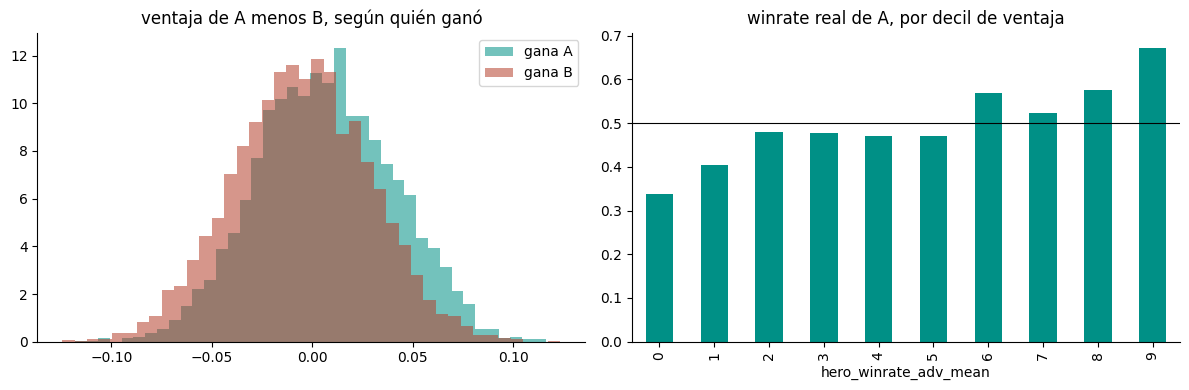

In [ ]:
# ¿Cómo se ven las dos distribuciones, y cómo sube el winrate real con la ventaja?
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, sel, color in [("gana A", gano_A, VERDE_AZUL), ("gana B", ~gano_A, TERRACOTA)]:
    ejes[0].hist(ventaja[sel], bins=40, alpha=.55, density=True, label=nombre, color=color)
ejes[0].set_title("ventaja de A menos B, según quién ganó"); ejes[0].legend()
deciles = pd.qcut(ventaja, 10, labels=False)
calibracion = gano_A.groupby(deciles).mean()
calibracion.plot(kind="bar", ax=ejes[1], color=VERDE_AZUL, title="winrate real de A, por decil de ventaja")
ejes[1].axhline(0.5, color="black", lw=.8)
plt.tight_layout()
plt.show()

In [ ]:
zona_h1 = semaforo(d_h1, "separacion")
assert zona_h1 == "amarillo"
leer(f"""**Resultado.** La separación es **{c(d_h1)}** (± {c(ee_h1)}): zona **{zona_h1}**. Los equipos ganadores tuvieron una ventaja teórica mayor, y la diferencia es real (varias veces el error), pero es una separación moderada. Es lo que anticipaba el boxplot.

**Qué se ve.** El histograma muestra dos campanas corridas que se pisan casi por completo. La curva de calibración es la prueba más clara de que la señal existe: el winrate real de A sube de **{calibracion.iloc[0]:.1%}** en el decil de menor ventaja a **{calibracion.iloc[-1]:.1%}** en el de mayor. Pero **no sube parejo**: hay tramos casi planos en el medio ({', '.join(f'{v:.1%}' for v in calibracion.iloc[2:6])} en los deciles 3 a 6). Eso es lo que justifica los dos movimientos, y por qué son *estos*: la meseta sugiere que en algún subgrupo la ventaja opera menos (partir la población), y la forma de escalera sugiere que el número crudo no es la escala natural (cambiar la escala).""")

**Resultado.** La separación es **0,348** (± 0,020): zona **amarillo**. Los equipos ganadores tuvieron una ventaja teórica mayor, y la diferencia es real (varias veces el error), pero es una separación moderada. Es lo que anticipaba el boxplot.

**Qué se ve.** El histograma muestra dos campanas corridas que se pisan casi por completo. La curva de calibración es la prueba más clara de que la señal existe: el winrate real de A sube de **33,7%** en el decil de menor ventaja a **67,3%** en el de mayor. Pero **no sube parejo**: hay tramos casi planos en el medio (48,0%, 47,7%, 47,1%, 47,0% en los deciles 3 a 6). Eso es lo que justifica los dos movimientos, y por qué son *estos*: la meseta sugiere que en algún subgrupo la ventaja opera menos (partir la población), y la forma de escalera sugiere que el número crudo no es la escala natural (cambiar la escala).

In [ ]:
# Movimiento 1, partir la población: ¿la separación cambia con el nivel de juego?
tramos = pd.cut(df["average_badge"], bins=[0, 40, 60, 80, 120], labels=["≤40", "41-60", "61-80", ">80"])
filas = []
for tramo, s in df.groupby(tramos, observed=True):
    a = s["winner"].eq("A")
    d = separacion(s.loc[a, "hero_winrate_adv_mean"], s.loc[~a, "hero_winrate_adv_mean"])
    filas.append({"tramo de badge": tramo, "partidas": len(s), "separación": d, "± error": error_separacion(d, a.sum(), (~a).sum()), "zona": semaforo(d, "separacion")})
por_tramo = pd.DataFrame(filas).set_index("tramo de badge")
por_tramo.round(3)

,partidas,separación,± error,zona
tramo de badge,,,,
≤40,3292,0.394,0.035,amarillo
41-60,2033,0.302,0.045,amarillo
61-80,2223,0.401,0.043,amarillo
>80,2451,0.272,0.041,amarillo


In [ ]:
# Movimiento 2, cambiar la escala: ¿y si se mide sobre el percentil en vez del valor crudo?
percentil = ventaja.rank(pct=True)
d_h1_pct = separacion(percentil[gano_A], percentil[~gano_A])
pd.Series({"separación (valor crudo)": round(d_h1, 3), "separación (percentil)": round(d_h1_pct, 3), "zona": semaforo(d_h1_pct, "separacion")})

separación (valor crudo)       0.348
separación (percentil)         0.333
zona                        amarillo
dtype: object

In [ ]:
zonas_tramo = set(por_tramo["zona"])
zona_pct = semaforo(d_h1_pct, "separacion")
assert zonas_tramo == {"amarillo"} and zona_pct == "amarillo", "algún movimiento cambió de zona: hay que reescribir el veredicto"
exactitud_umbral = ((ventaja > 0) == gano_A).mean()
piso = max(gano_A.mean(), 1 - gano_A.mean())
leer(f"""**Movimiento 1: partir por nivel de juego.** En los cuatro tramos de badge la separación queda entre **{c(por_tramo['separación'].min())}** y **{c(por_tramo['separación'].max())}**, siempre amarilla. Varía de un tramo a otro (con error de ±{c(por_tramo['± error'].mean(), 2)} en cada uno, la diferencia entre el máximo y el mínimo es de unos dos errores combinados: suficiente para notarla, poco para sacar una regla de cuatro tramos), pero **no cambia de zona**: partir la población no desarma el efecto ni lo lleva a verde. No es monótona con el nivel, así que tampoco sostiene una historia simple de "a más rango, más importa la composición".

**Movimiento 2: cambiar la escala.** Sobre el percentil la separación es **{c(d_h1_pct)}**, casi igual a la del valor crudo ({c(d_h1)}), y sigue en amarillo. La forma de escalera de la calibración no era un problema de escala.

**Resultado tras los dos movimientos.** Sigue amarillo. Por la regla de la cátedra, la conclusión es **inconclusa**: la ventaja teórica separa a los equipos de forma real y estable, pero moderada, y ninguna manera de cortarla la lleva a verde ni a rojo.

**Qué hago con eso.** La columna **entra al modelo**: junto con las otras dos ventajas de winrate (que H3 muestra casi idénticas) es la de mayor separación del dataset, y `average_badge` queda como variable para *segmentar* resultados, no como feature. Lo que hay que llevarse a la Entrega 3 es una expectativa realista: una regla de un solo umbral ("gana A si su ventaja es positiva") acierta el **{exactitud_umbral:.1%}** de las partidas, contra un piso de {piso:.1%}. Ese número es el punto de partida: un modelo que use además las interacciones entre héroes tiene que superarlo para justificarse. Lo que quedó sin resolver es *cuánto* de lo que falta es composición que el modelo puede aprender y cuánto es ruido irreducible de una partida de seis contra seis.""")
RES["H1"] = dict(pregunta="responder", plantilla="comparación", medida=f"separación {c(d_h1)} → tramos {c(por_tramo['separación'].min())}–{c(por_tramo['separación'].max())} → percentil {c(d_h1_pct)}",
                 zona="amarillo", decision="inconclusa: la ventaja entra al modelo; línea base de un umbral = " + f"{exactitud_umbral:.1%}")

**Movimiento 1: partir por nivel de juego.** En los cuatro tramos de badge la separación queda entre **0,272** y **0,401**, siempre amarilla. Varía de un tramo a otro (con error de ±0,04 en cada uno, la diferencia entre el máximo y el mínimo es de unos dos errores combinados: suficiente para notarla, poco para sacar una regla de cuatro tramos), pero **no cambia de zona**: partir la población no desarma el efecto ni lo lleva a verde. No es monótona con el nivel, así que tampoco sostiene una historia simple de "a más rango, más importa la composición".

**Movimiento 2: cambiar la escala.** Sobre el percentil la separación es **0,333**, casi igual a la del valor crudo (0,348), y sigue en amarillo. La forma de escalera de la calibración no era un problema de escala.

**Resultado tras los dos movimientos.** Sigue amarillo. Por la regla de la cátedra, la conclusión es **inconclusa**: la ventaja teórica separa a los equipos de forma real y estable, pero moderada, y ninguna manera de cortarla la lleva a verde ni a rojo.

**Qué hago con eso.** La columna **entra al modelo**: junto con las otras dos ventajas de winrate (que H3 muestra casi idénticas) es la de mayor separación del dataset, y `average_badge` queda como variable para *segmentar* resultados, no como feature. Lo que hay que llevarse a la Entrega 3 es una expectativa realista: una regla de un solo umbral ("gana A si su ventaja es positiva") acierta el **56,5%** de las partidas, contra un piso de 50,2%. Ese número es el punto de partida: un modelo que use además las interacciones entre héroes tiene que superarlo para justificarse. Lo que quedó sin resolver es *cuánto* de lo que falta es composición que el modelo puede aprender y cuánto es ruido irreducible de una partida de seis contra seis.

## H2 · Los héroes más elegidos son los que más ganan

**Pregunta:** de dominio. **Plantilla:** asociación.

**Afirmación.** Entre los 38 héroes, los de mayor pick rate son también los de mayor winrate.

**Qué espero ver.** Una relación positiva, de tamaño intermedio: si los jugadores eligen razonablemente bien, lo popular debería tender a rendir, pero la popularidad también responde a la moda y a la facilidad de uso. Espero una correlación en zona amarilla.

**Por qué esta medida.** Es asociación entre dos numéricas, así que Pearson y Spearman **juntos**. La brecha entre ambos avisa si la relación es ordenada pero curva. Ojo con el tamaño: son solo **38 observaciones** (una por héroe), no 10.000, y con tan pocas hay que mirar también cuánto se mueve la correlación por azar.

In [ ]:
# ¿Se mueven juntos el pick rate y el winrate de los héroes?
h2 = asociacion(heroes["pickrate"], heroes["winrate"])
lo, hi = intervalo_correlacion(h2["pearson"], len(heroes))
pd.Series({**h2.to_dict(), "IC95% pearson": f"[{lo:.2f}, {hi:.2f}]",
           "zona correlación": semaforo(h2["spearman"], "correlacion"), "zona brecha": semaforo(h2["brecha"], "brecha")})

pearson                     0.275
spearman                    0.378
brecha                      0.103
IC95% pearson       [-0.05, 0.55]
zona correlación         amarillo
zona brecha              amarillo
dtype: object

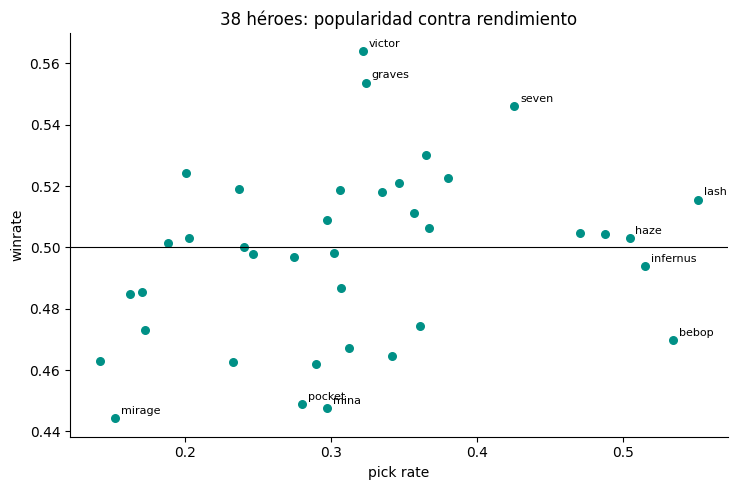

In [ ]:
# ¿Quiénes son los héroes que se apartan de la relación?
fig, eje = plt.subplots(figsize=(7.5, 5))
eje.scatter(heroes["pickrate"], heroes["winrate"], color=VERDE_AZUL, s=30)
extremos = pd.concat([heroes["pickrate"].nlargest(4), heroes["winrate"].nsmallest(3), heroes["winrate"].nlargest(3)]).index.unique()
for nombre in extremos:
    eje.annotate(nombre, (heroes.loc[nombre, "pickrate"], heroes.loc[nombre, "winrate"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
eje.axhline(0.5, color="black", lw=.8)
eje.set_xlabel("pick rate"); eje.set_ylabel("winrate"); eje.set_title("38 héroes: popularidad contra rendimiento")
plt.tight_layout()
plt.show()

In [ ]:
pop_malos = heroes[(heroes["pickrate"] > heroes["pickrate"].median()) & (heroes["winrate"] < 0.5)].sort_values("pickrate", ascending=False)
zona_c, zona_b = semaforo(h2["spearman"], "correlacion"), semaforo(h2["brecha"], "brecha")
assert zona_c == "amarillo" and zona_b == "amarillo"
leer(f"""**Resultado.** Pearson **{c(h2['pearson'])}**, Spearman **{c(h2['spearman'])}**, brecha **{c(h2['brecha'])}**: la correlación cae en **{zona_c}** y la brecha también en **{zona_b}**. Hay una relación positiva, pero el intervalo de confianza del Pearson va de {c(lo, 2)} a {c(hi, 2)}: **incluye el cero**. Con 38 héroes no se puede descartar que el {c(h2['pearson'])} sea puro azar.

**Qué se ve.** La nube tiene una tendencia leve hacia arriba y bastante dispersión. Hay héroes populares que **rinden por debajo del 50 %**: {', '.join(f'`{n}` ({r.pickrate:.0%} de pick, {r.winrate:.1%} de winrate)' for n, r in pop_malos.head(3).iterrows())}. Esos casos explican la brecha: los rangos (Spearman) captan la tendencia mejor que los valores (Pearson) porque unos pocos héroes muy elegidos y poco efectivos tiran de la recta. Eso justifica el primer movimiento (cambiar la escala). Y la pregunta natural sobre esos héroes populares y flojos es si su popularidad viene de quienes los juegan, que justifica el segundo (partir por nivel de juego).""")

**Resultado.** Pearson **0,275**, Spearman **0,378**, brecha **0,103**: la correlación cae en **amarillo** y la brecha también en **amarillo**. Hay una relación positiva, pero el intervalo de confianza del Pearson va de -0,05 a 0,55: **incluye el cero**. Con 38 héroes no se puede descartar que el 0,275 sea puro azar.

**Qué se ve.** La nube tiene una tendencia leve hacia arriba y bastante dispersión. Hay héroes populares que **rinden por debajo del 50 %**: `bebop` (53% de pick, 47,0% de winrate), `infernus` (51% de pick, 49,4% de winrate), `billy` (36% de pick, 47,5% de winrate). Esos casos explican la brecha: los rangos (Spearman) captan la tendencia mejor que los valores (Pearson) porque unos pocos héroes muy elegidos y poco efectivos tiran de la recta. Eso justifica el primer movimiento (cambiar la escala). Y la pregunta natural sobre esos héroes populares y flojos es si su popularidad viene de quienes los juegan, que justifica el segundo (partir por nivel de juego).

In [ ]:
# Movimiento 1, cambiar la escala: ¿el pick rate en escala logarítmica aclara la relación?
h2_log = asociacion(np.log(heroes["pickrate"]), heroes["winrate"])
pd.Series({"pearson (pick rate crudo)": h2["pearson"], "pearson (log del pick rate)": h2_log["pearson"], "brecha tras el log": h2_log["brecha"],
           "zona correlación": semaforo(h2_log["pearson"], "correlacion"), "zona brecha": semaforo(h2_log["brecha"], "brecha")})

pearson (pick rate crudo)         0.275
pearson (log del pick rate)        0.32
brecha tras el log                0.057
zona correlación               amarillo
zona brecha                    amarillo
dtype: object

In [ ]:
# Movimiento 2, partir la población: ¿los jugadores de rango alto eligen mejor?
mediana_badge = df["average_badge"].median()
h2_partido = {}
for nombre, sel in [("badge bajo", df["average_badge"] < mediana_badge), ("badge alto", df["average_badge"] >= mediana_badge)]:
    t = tabla_heroes(df[sel])
    h2_partido[nombre] = {"partidas": int(sel.sum()), **asociacion(t["pickrate"], t["winrate"]).to_dict()}
    h2_partido[nombre]["zona"] = semaforo(h2_partido[nombre]["spearman"], "correlacion")
pd.DataFrame(h2_partido).T

,partidas,pearson,spearman,brecha,zona
badge bajo,4932,0.324,0.343,0.019,amarillo
badge alto,5067,0.163,0.231,0.069,amarillo


In [ ]:
zonas_final = {semaforo(h2_log["pearson"], "correlacion"), *(v["zona"] for v in h2_partido.values())}
assert "verde" not in zonas_final, "algún movimiento llegó a verde: hay que reescribir el veredicto"
leer(f"""**Movimiento 1: escala logarítmica.** El Pearson pasa de {c(h2['pearson'])} a **{c(h2_log['pearson'])}** y la brecha baja de {c(h2['brecha'])} a {c(h2_log['brecha'])}: la relación tenía algo de curva y el log la endereza un poco. Sigue en amarillo.

**Movimiento 2: partir por nivel de juego.** En los partidos de badge bajo la correlación de Spearman es **{c(h2_partido['badge bajo']['spearman'])}** y en los de badge alto **{c(h2_partido['badge alto']['spearman'])}**. En el rango alto la relación se **debilita** ({h2_partido['badge alto']['zona']}), una pista de que la popularidad es mejor guía cuando juega gente de menor nivel, y de que los jugadores fuertes eligen por otras razones. Pero cada mitad tiene solo 38 héroes y sus propios intervalos anchos.

**Resultado tras los dos movimientos.** Ninguna versión llega a verde. En el rango alto el Pearson ({c(h2_partido['badge alto']['pearson'])}) cae en rojo y el Spearman apenas en amarillo: no hay una lectura única. La conclusión es **inconclusa**: hay una tendencia positiva débil que el tamaño de la muestra (38 héroes) no permite confirmar ni descartar.

**Qué hago con eso.** Para el modelo, la decisión es **no construir ninguna feature de popularidad**: la asociación es débil y no está confirmada, y calcularla sobre las mismas partidas que se predicen sería otra forma de fuga (habría que traerla de la ventana previa). El desbalance de picks de la sección 2 se lee, entonces, como sesgo de la muestra, no como señal. **Qué haría falta para resolverlo:** más de un corte temporal. Cada corte agrega otras 38 observaciones (pick rate y winrate de esa fecha), y con seis o siete cortes la correlación deja de depender de un solo día.""")
RES["H2"] = dict(pregunta="responder", plantilla="asociación", medida=f"Pearson {c(h2['pearson'])}, brecha {c(h2['brecha'])} → log {c(h2_log['pearson'])} → badge alto {c(h2_partido['badge alto']['spearman'])}",
                 zona="amarillo", decision="inconclusa: no se construye feature de popularidad")

**Movimiento 1: escala logarítmica.** El Pearson pasa de 0,275 a **0,320** y la brecha baja de 0,103 a 0,057: la relación tenía algo de curva y el log la endereza un poco. Sigue en amarillo.

**Movimiento 2: partir por nivel de juego.** En los partidos de badge bajo la correlación de Spearman es **0,343** y en los de badge alto **0,231**. En el rango alto la relación se **debilita** (amarillo), una pista de que la popularidad es mejor guía cuando juega gente de menor nivel, y de que los jugadores fuertes eligen por otras razones. Pero cada mitad tiene solo 38 héroes y sus propios intervalos anchos.

**Resultado tras los dos movimientos.** Ninguna versión llega a verde. En el rango alto el Pearson (0,163) cae en rojo y el Spearman apenas en amarillo: no hay una lectura única. La conclusión es **inconclusa**: hay una tendencia positiva débil que el tamaño de la muestra (38 héroes) no permite confirmar ni descartar.

**Qué hago con eso.** Para el modelo, la decisión es **no construir ninguna feature de popularidad**: la asociación es débil y no está confirmada, y calcularla sobre las mismas partidas que se predicen sería otra forma de fuga (habría que traerla de la ventana previa). El desbalance de picks de la sección 2 se lee, entonces, como sesgo de la muestra, no como señal. **Qué haría falta para resolverlo:** más de un corte temporal. Cada corte agrega otras 38 observaciones (pick rate y winrate de esa fecha), y con seis o siete cortes la correlación deja de depender de un solo día.

## H3 · Los tres bloques de winrate miden lo mismo

**Pregunta:** de modelado. **Plantilla:** asociación.

**Afirmación.** `counter_winrate_adv_mean`, `synergy_winrate_adv_mean` y `hero_winrate_adv_mean` son, en la práctica, la misma información, y dos de las tres sobran.

**Qué espero ver.** Correlaciones muy altas, en verde. Los tres bloques salen de tablas de estadísticas distintas (cruces, parejas y héroes sueltos) pero se construyen con la misma fórmula de *shrinkage* sobre las mismas partidas, así que no deberían aportar información independiente. Pero un `0,9` no es lo mismo que un `0,99`, y lo que decide si una columna se borra es qué tanto queda *afuera* de la otra.

**Por qué esta medida.** Es asociación: Pearson y Spearman. Un tercer par aporta contraste: las columnas de souls y de kills, que salen de las mismas tablas de counters pero miden otra cosa, y que si esto fuera un artefacto del *prefijo* también deberían salir pegadas.

In [ ]:
# ¿Cuánto se parecen las tres ventajas de winrate, y cuánto las que miden otra cosa?
ancla = df["hero_winrate_adv_mean"]
comparar = ["counter_winrate_adv_mean", "synergy_winrate_adv_mean", "counter_souls_adv_mean", "counter_kills_adv_mean"]
h3 = pd.DataFrame({k: asociacion(ancla, df[k]) for k in comparar}).T
h3["zona"] = h3["pearson"].map(lambda v: semaforo(v, "correlacion"))
h3

,pearson,spearman,brecha,zona
counter_winrate_adv_mean,0.998,0.998,-0.000,verde
synergy_winrate_adv_mean,0.988,0.987,-0.000,verde
counter_souls_adv_mean,0.499,0.483,-0.016,amarillo
counter_kills_adv_mean,0.060,0.060,0.001,rojo


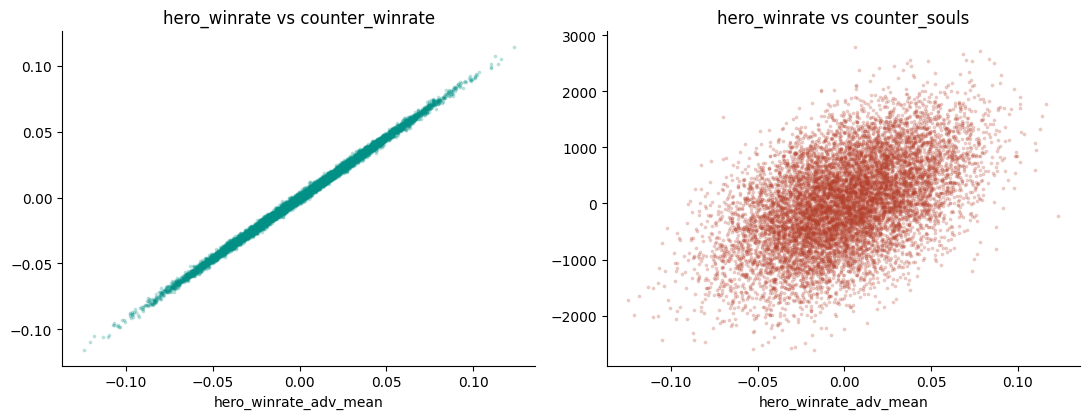

In [ ]:
# ¿Qué forma tiene la relación entre las ventajas?
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.3))
ejes[0].scatter(ancla, df["counter_winrate_adv_mean"], s=3, alpha=.2, color=VERDE_AZUL)
ejes[0].set_title("hero_winrate vs counter_winrate"); ejes[0].set_xlabel("hero_winrate_adv_mean")
ejes[1].scatter(ancla, df["counter_souls_adv_mean"], s=3, alpha=.2, color=TERRACOTA)
ejes[1].set_title("hero_winrate vs counter_souls"); ejes[1].set_xlabel("hero_winrate_adv_mean")
plt.tight_layout()
plt.show()

In [ ]:
r_c, r_s, r_souls, r_kills = (h3.loc[k, "pearson"] for k in comparar)
assert h3.loc["counter_winrate_adv_mean", "zona"] == "verde" and h3.loc["synergy_winrate_adv_mean", "zona"] == "verde"
assert abs(r_souls) < 0.6 and abs(r_kills) < 0.2
leer(f"""**Resultado.** `counter_winrate_adv_mean` correlaciona **{c(r_c)}** con `hero_winrate_adv_mean` y `synergy_winrate_adv_mean` **{c(r_s)}**: ambas en **verde**, sin necesidad de movimientos. Casi no queda información de una que no esté en la otra.

**Qué se ve.** La primera nube es una recta casi perfecta. La segunda, la de souls, es una nube ancha: relación positiva, pero **{c(r_souls, 2)}** de Pearson, muy lejos de la redundancia. Y `counter_kills_adv_mean` está en **{c(r_kills, 2)}**: independiente. El contraste es lo que importa, porque descarta que esto sea un efecto del nombre o de que las columnas salgan de la misma tabla. Las de souls y kills también salen de las tablas de counters, y no son redundantes.

**Por qué da tan alto, y no es casualidad.** `counter_winrate_adv_mean` es el promedio de la tasa de victoria de cada héroe de A *contra* cada héroe de B, sobre los 36 cruces. Pero la tasa de un héroe contra otro ya descuenta la fuerza del rival: cuando A enfrenta a un B fuerte, gana menos. Promediado sobre los 36 cruces, eso **reconstruye la diferencia de fuerza media entre los dos equipos**, que es exactamente lo que mide `hero_winrate_adv_mean` (promedio de A menos promedio de B). Dos rutas distintas hacia el mismo número. Con las parejas internas (`synergy`) pasa algo parecido.

**Qué hago con eso.** Se queda `hero_winrate_adv_mean`: es la más simple de explicar y de calcular (una tabla de 38 filas). **Salen `counter_winrate_adv_mean` y `synergy_winrate_adv_mean`**: dos columnas menos, decididas con un número y no con el prefijo. Las de souls y kills **no salen**, porque el mismo número dice que aportan otra cosa. Los `min`, `max` y `std` de cada bloque se evalúan aparte en la tabla final, cada uno con su propio número.""")
RES["H3"] = dict(pregunta="predecir", plantilla="asociación", medida=f"r = {c(r_c)} (counter), {c(r_s)} (synergy); souls {c(r_souls, 2)}, kills {c(r_kills, 2)}",
                 zona="verde", decision="confirmada: salen counter_winrate_mean y synergy_winrate_mean")

**Resultado.** `counter_winrate_adv_mean` correlaciona **0,998** con `hero_winrate_adv_mean` y `synergy_winrate_adv_mean` **0,988**: ambas en **verde**, sin necesidad de movimientos. Casi no queda información de una que no esté en la otra.

**Qué se ve.** La primera nube es una recta casi perfecta. La segunda, la de souls, es una nube ancha: relación positiva, pero **0,50** de Pearson, muy lejos de la redundancia. Y `counter_kills_adv_mean` está en **0,06**: independiente. El contraste es lo que importa, porque descarta que esto sea un efecto del nombre o de que las columnas salgan de la misma tabla. Las de souls y kills también salen de las tablas de counters, y no son redundantes.

**Por qué da tan alto, y no es casualidad.** `counter_winrate_adv_mean` es el promedio de la tasa de victoria de cada héroe de A *contra* cada héroe de B, sobre los 36 cruces. Pero la tasa de un héroe contra otro ya descuenta la fuerza del rival: cuando A enfrenta a un B fuerte, gana menos. Promediado sobre los 36 cruces, eso **reconstruye la diferencia de fuerza media entre los dos equipos**, que es exactamente lo que mide `hero_winrate_adv_mean` (promedio de A menos promedio de B). Dos rutas distintas hacia el mismo número. Con las parejas internas (`synergy`) pasa algo parecido.

**Qué hago con eso.** Se queda `hero_winrate_adv_mean`: es la más simple de explicar y de calcular (una tabla de 38 filas). **Salen `counter_winrate_adv_mean` y `synergy_winrate_adv_mean`**: dos columnas menos, decididas con un número y no con el prefijo. Las de souls y kills **no salen**, porque el mismo número dice que aportan otra cosa. Los `min`, `max` y `std` de cada bloque se evalúan aparte en la tabla final, cada uno con su propio número.

## H4 · El equipo con los jugadores de mejor rango gana

**Pregunta:** de modelado. **Plantilla:** comparación.

**Afirmación.** Cuando el equipo A tiene un rango promedio mayor que el B (`average_badge_diff > 0`), gana más seguido, y esa diferencia es lo bastante grande como para justificar la columna.

**Qué espero ver.** Que exista una relación. Parece obvio: el rango existe para medir habilidad, y `average_badge_diff` resume justamente esa diferencia entre equipos. Espero una separación en zona **amarilla o verde**, y una curva de calibración que suba con la diferencia de rango.

**Por qué esta medida.** Es una comparación de dos grupos (ganadores y perdedores) sobre una numérica, así que la misma separación estandarizada de H1, con el mismo semáforo, para que las dos hipótesis sean comparables. Como el rango se codifica como `tier*10+subrank` (sección 4), se agrega una prueba de robustez con el rango linealizado y sin los jugadores en calibración.

**Sobre el chequeo de fuga.** Esta columna **existiría al predecir**: es el rango *inicial* de cada jugador, conocido antes del primer minuto. No es fuga. La pregunta es solo si aporta.

In [ ]:
# ¿Cuántos desvíos separan la diferencia de rango de los que ganan y de los que pierden?
dif = df["average_badge_diff"]
d_h4 = separacion(dif[gano_A], dif[~gano_A])
ee_h4 = error_separacion(d_h4, gano_A.sum(), (~gano_A).sum())
pd.Series({"separación": round(d_h4, 3), "± error": round(ee_h4, 3), "zona": semaforo(d_h4, "separacion")})

separación    0.041
± error        0.02
zona           rojo
dtype: object

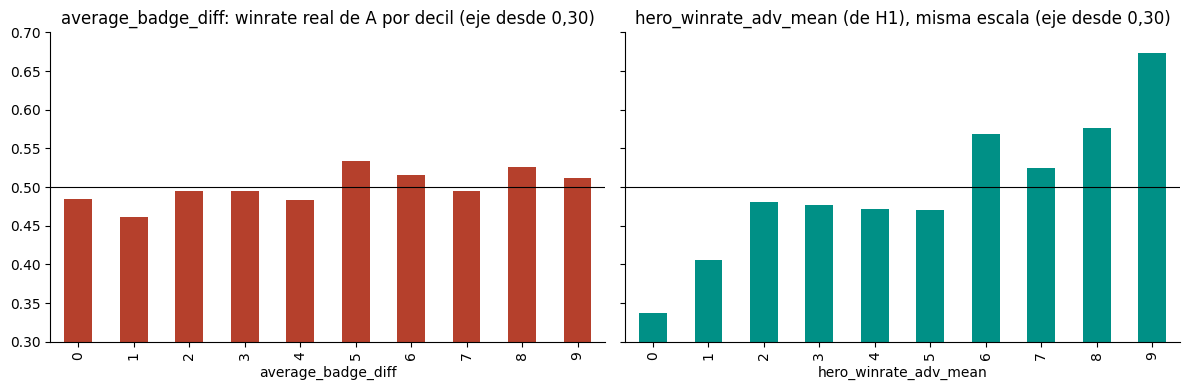

In [ ]:
# ¿Sube el winrate real de A cuando su equipo tiene mejor rango?
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
cal_dif = gano_A.groupby(pd.qcut(dif, 10, labels=False, duplicates="drop")).mean()
cal_dif.plot(kind="bar", ax=ejes[0], color=TERRACOTA, title="average_badge_diff: winrate real de A por decil (eje desde 0,30)")
cal_hero = gano_A.groupby(pd.qcut(ventaja, 10, labels=False)).mean()
cal_hero.plot(kind="bar", ax=ejes[1], color=VERDE_AZUL, title="hero_winrate_adv_mean (de H1), misma escala (eje desde 0,30)")
for eje in ejes:
    eje.axhline(0.5, color="black", lw=.8); eje.set_ylim(0.3, 0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Prueba de robustez: rango linealizado (tier*6 + subrank), con y sin los jugadores en calibración
def promedio_lineal(jugadores, incluir_calibrando):
    v = [(p["player_rank_initial_display_rank"] // 10) * 6 + p["player_rank_initial_display_rank"] % 10
         for p in jugadores if incluir_calibrando or p["player_rank_initial_display_rank"] > 0]
    return np.mean(v) if v else np.nan


lin_con, lin_sin = {}, {}
for m in crudas:
    b = parse_match(m)
    if b is None:
        continue
    equipos = {t: [p for p in m["players"] if p["team"] == t] for t in ("Team0", "Team1")}
    lin_con[b["match_id"]] = promedio_lineal(equipos["Team0"], True) - promedio_lineal(equipos["Team1"], True)
    lin_sin[b["match_id"]] = promedio_lineal(equipos["Team0"], False) - promedio_lineal(equipos["Team1"], False)
variantes = {"rango original (el del CSV)": dif, "linealizado": df["match_id"].map(lin_con), "linealizado y sin calibrando": df["match_id"].map(lin_sin)}
robustez = pd.DataFrame({nombre: {"separación": separacion(v[gano_A], v[~gano_A]), "partidas": int(v.notna().sum())} for nombre, v in variantes.items()}).T
robustez["zona"] = robustez["separación"].map(lambda v: semaforo(v, "separacion"))
robustez.round(3)

,separación,partidas,zona
rango original (el del CSV),0.041,9999.0,rojo
linealizado,0.045,9999.0,rojo
linealizado y sin calibrando,0.070,9998.0,rojo


In [ ]:
zona_h4 = semaforo(d_h4, "separacion")
assert zona_h4 == "rojo" and (robustez["zona"] == "rojo").all(), "la refutación dejó de valer en alguna variante"
d_lineal = robustez.loc["linealizado y sin calibrando", "separación"]
error_decil = np.sqrt(0.25 / (len(df) / 10))
grandes = dif.abs() >= 10
gana_mayor = ((dif[grandes] > 0) == gano_A[grandes]).mean()
mediana_abs = dif.abs().median()
leer(f"""**Resultado.** La separación es **{c(d_h4)}** (± {c(ee_h4)}): zona **{zona_h4}**. La diferencia de rango entre los equipos casi no separa a ganadores de perdedores, y el valor es apenas distinguible de cero.

**Qué se ve.** La curva de calibración de `average_badge_diff` es **casi plana**: entre el primer y el último decil el winrate de A pasa de {cal_dif.iloc[0]:.1%} a {cal_dif.iloc[-1]:.1%}, {abs(cal_dif.iloc[-1] - cal_dif.iloc[0]) * 100:.1f} puntos, cuando cada decil tiene un error de ±{c(100 * error_decil, 1)} puntos. Hay una deriva leve hacia arriba (sería raro que fuera exactamente cero), pero es diminuta. A su lado, la ventaja de composición de H1 (misma escala vertical) sube de {cal_hero.iloc[0]:.1%} a {cal_hero.iloc[-1]:.1%}. Es la comparación que decide: **el rango previo aporta mucho menos que la composición**.

**El caso más favorable.** Si en algún lado el rango tenía que importar es en las partidas con la mayor brecha. En el {grandes.mean():.0%} de las partidas los equipos difieren en 10 o más puntos de rango, y el de mayor rango gana el **{gana_mayor:.1%}** de ellas. Ni siquiera ahí se ve.

**Prueba de robustez.** Como el rango tiene saltos y trata a los jugadores en calibración como rango 0 (sección 4), se repitió la medida de tres maneras: con el rango del CSV ({c(robustez.iloc[0, 0])}), linealizado ({c(robustez.iloc[1, 0])}) y linealizado sin contar a los que están calibrando ({c(robustez.iloc[2, 0])}). Las tres son **rojo**. La refutación **no es un artefacto de la codificación ni del cero de calibración**. (Esto es una verificación de que la medida es válida, no un movimiento: en rojo la hipótesis termina, y no se pueden probar variantes hasta que dé.)

**Veredicto: refutada.** Sin movimientos, porque el rojo termina la hipótesis.

**Por qué puede ser así, una lectura de dominio.** La mediana de |`average_badge_diff`| es de **{c(mediana_abs, 1)}** puntos, contra un desvío de **{c(df['average_badge'].std(), 1)}** en el `average_badge` entre partidas: el emparejamiento ya iguala a los equipos por rango, así que la diferencia que queda es chica y no tiene de dónde predecir. Es evidencia de que el *matchmaking* funciona, una conclusión sobre el juego y no solo sobre la columna.

**Qué hago con eso.** `average_badge_diff` **sale**. Y la distinción que importa para la defensa: **sale por inútil, no por tramposa**. Pasa el chequeo de fuga sin problema (existe antes de jugar), y aun así no aporta. Son dos preguntas independientes: una columna puede ser legítima y no servir. Lo que sigue abierto es si tiene *interacción* con la composición (por ejemplo, que la composición importe más cuando los rangos son parejos), algo que una comparación marginal como ésta no puede ver y que la Entrega 3 va a poder probar con un modelo.""")
RES["H4"] = dict(pregunta="predecir", plantilla="comparación", medida=f"separación {c(d_h4)} (robustez: {c(robustez.iloc[1, 0])} y {c(robustez.iloc[2, 0])})",
                 zona="rojo", decision="refutada: average_badge_diff sale, por inútil y no por fuga")

**Resultado.** La separación es **0,041** (± 0,020): zona **rojo**. La diferencia de rango entre los equipos casi no separa a ganadores de perdedores, y el valor es apenas distinguible de cero.

**Qué se ve.** La curva de calibración de `average_badge_diff` es **casi plana**: entre el primer y el último decil el winrate de A pasa de 48,4% a 51,1%, 2,7 puntos, cuando cada decil tiene un error de ±1,6 puntos. Hay una deriva leve hacia arriba (sería raro que fuera exactamente cero), pero es diminuta. A su lado, la ventaja de composición de H1 (misma escala vertical) sube de 33,7% a 67,3%. Es la comparación que decide: **el rango previo aporta mucho menos que la composición**.

**El caso más favorable.** Si en algún lado el rango tenía que importar es en las partidas con la mayor brecha. En el 23% de las partidas los equipos difieren en 10 o más puntos de rango, y el de mayor rango gana el **51,3%** de ellas. Ni siquiera ahí se ve.

**Prueba de robustez.** Como el rango tiene saltos y trata a los jugadores en calibración como rango 0 (sección 4), se repitió la medida de tres maneras: con el rango del CSV (0,041), linealizado (0,045) y linealizado sin contar a los que están calibrando (0,070). Las tres son **rojo**. La refutación **no es un artefacto de la codificación ni del cero de calibración**. (Esto es una verificación de que la medida es válida, no un movimiento: en rojo la hipótesis termina, y no se pueden probar variantes hasta que dé.)

**Veredicto: refutada.** Sin movimientos, porque el rojo termina la hipótesis.

**Por qué puede ser así, una lectura de dominio.** La mediana de |`average_badge_diff`| es de **2,7** puntos, contra un desvío de **24,9** en el `average_badge` entre partidas: el emparejamiento ya iguala a los equipos por rango, así que la diferencia que queda es chica y no tiene de dónde predecir. Es evidencia de que el *matchmaking* funciona, una conclusión sobre el juego y no solo sobre la columna.

**Qué hago con eso.** `average_badge_diff` **sale**. Y la distinción que importa para la defensa: **sale por inútil, no por tramposa**. Pasa el chequeo de fuga sin problema (existe antes de jugar), y aun así no aporta. Son dos preguntas independientes: una columna puede ser legítima y no servir. Lo que sigue abierto es si tiene *interacción* con la composición (por ejemplo, que la composición importe más cuando los rangos son parejos), algo que una comparación marginal como ésta no puede ver y que la Entrega 3 va a poder probar con un modelo.

### Las cuatro hipótesis, juntas

In [ ]:
# Las cuatro hipótesis, su medida y la decisión que salió de cada una
pd.DataFrame([{"hipótesis": h, **v} for h, v in RES.items()]).set_index("hipótesis")[["pregunta", "plantilla", "medida", "zona", "decision"]]

,pregunta,plantilla,medida,zona,decision
hipótesis,,,,,
H1,responder,comparación,"separación 0,348 → tramos 0,272–0,401 → percentil 0,333",amarillo,inconclusa: la ventaja entra al modelo; línea base de un umbral = 56.5%
H2,responder,asociación,"Pearson 0,275, brecha 0,103 → log 0,320 → badge alto 0,231",amarillo,inconclusa: no se construye feature de popularidad
H3,predecir,asociación,"r = 0,998 (counter), 0,988 (synergy); souls 0,50, kills 0,06",verde,confirmada: salen counter_winrate_mean y synergy_winrate_mean
H4,predecir,comparación,"separación 0,041 (robustez: 0,045 y 0,070)",rojo,"refutada: average_badge_diff sale, por inútil y no por fuga"


In [ ]:
leer(f"""Se cumplen las condiciones de la consigna: **dos hipótesis de dominio** (H1, H2) y **dos que deciden una columna** (H3, H4); **tres no confirmadas** (H1 inconclusa, H2 inconclusa, H4 refutada) contra una confirmada (H3); **ninguna con más de dos movimientos**; y cada resultado con su número y su zona.""")

Se cumplen las condiciones de la consigna: **dos hipótesis de dominio** (H1, H2) y **dos que deciden una columna** (H3, H4); **tres no confirmadas** (H1 inconclusa, H2 inconclusa, H4 refutada) contra una confirmada (H3); **ninguna con más de dos movimientos**; y cada resultado con su número y su zona.

# Sección 8: La tabla de columnas candidatas

Una fila por columna. La construcción es programática: cada zona sale de la separación real de esa columna contra `winner`, y las redundancias salen de una regla aplicada a los números, no de una lista escrita a mano.

**La regla de redundancia** extiende H3 a todas las columnas de ventaja: se parte de `hero_winrate_adv_mean` y se recorren las demás de mayor a menor separación; una columna **sale por redundante** si correlaciona más de 0,6 (la zona verde de la cátedra) con una que ya se quedó.

In [ ]:
# La separación de cada columna contra el objetivo, y qué familia es
numericas = [k for k in df.columns if k not in ("match_id", "match_date", "game_mode", "match_mode", "winner") and df[k].nunique() > 1]
sep_col = pd.Series({k: separacion(df.loc[gano_A, k], df.loc[~gano_A, k]) for k in numericas})
ventajas_cols = [k for k in numericas if FAMILIAS[k].startswith(("counter", "hero_winrate"))]
sep_col[ventajas_cols].sort_values(ascending=False).round(3).head(8)

counter_winrate_adv_mean    0.351
hero_winrate_adv_mean       0.348
synergy_winrate_adv_mean    0.346
synergy_winrate_adv_max     0.287
synergy_winrate_adv_min     0.258
counter_winrate_adv_max     0.256
hero_winrate_adv_max        0.252
counter_winrate_adv_min     0.244
dtype: float64

In [ ]:
# La regla de redundancia, aplicada en orden de separación
quedan = ["hero_winrate_adv_mean"]
redundante_con = {}
for k in sep_col[ventajas_cols].sort_values(ascending=False).index:
    if k in quedan:
        continue
    r = df[quedan].corrwith(df[k]).abs()
    if r.max() > 0.6:
        redundante_con[k] = (r.idxmax(), r.max())
    else:
        quedan.append(k)
pd.Series({"ventaja que se quedan": len(quedan), "ventaja que salen por redundantes": len(redundante_con)})

ventaja que se quedan                16
ventaja que salen por redundantes    12
dtype: int64

In [ ]:
# La tabla: qué mide, zona, decisión y chequeo de fuga, una columna por vez
DESCRIPCION = {"match_id": "Identificador de la partida", "match_date": "Fecha de la partida", "game_mode": "Modo de juego (filtro de la descarga)",
               "match_mode": "Modo de la cola (filtro de la descarga)", "average_badge": "Rango promedio de la partida (API)",
               "average_badge_diff": "Rango inicial promedio de A menos B (reconstruido)", "winner": "Equipo ganador: A o B"}
METRICA = {"winrate": "tasa de victoria", "kills": "diferencia de kills", "deaths": "diferencia de muertes", "assists": "diferencia de asistencias", "souls": "diferencia de souls"}


def que_mide(k):
    if k in DESCRIPCION:
        return DESCRIPCION[k]
    if FAMILIAS[k].startswith("composición"):
        return f"Si {k[5:]} juega: +1 en A, −1 en B, 0 si no participa"
    partes = k.split("_")
    agregado = partes[-1]
    if k.startswith("counter"):
        return f"{agregado} de {METRICA[partes[1]]} sobre los 36 cruces A×B"
    if k.startswith("synergy"):
        return f"{agregado} de sinergia de las parejas de A menos las de B"
    return f"{agregado} de la ventaja individual de los 6 héroes de A menos B"


def zona_de(k):
    return semaforo(sep_col[k], "separacion") if k in sep_col.index else "—"


def decision(k):
    if k == "winner":
        return "Objetivo", "es lo que se predice"
    if k == "match_id":
        return "Sale", "identificador, 0 duplicados"
    if k in ("match_date", "game_mode", "match_mode"):
        return "Sale", "constante: nunique = 1"
    if k == "average_badge_diff":
        return "Sale", f"H4: d = {sep_col[k]:.3f}, rojo y calibración plana"
    if k == "average_badge":
        return "Sale (segmenta)", f"d = {sep_col[k]:.3f}; simétrica entre equipos, sirve para partir población"
    if FAMILIAS[k].startswith("composición"):
        return "Entra (interacciones)", f"d = {sep_col[k]:.3f} (rojo solo); su aporte son las interacciones, a validar en Entrega 3"
    if k in redundante_con:
        otra, r = redundante_con[k]
        return "Sale", f"redundante: r = {r:.3f} con {otra}"
    if df[k].std() > 0.1:
        return "Entra, estandarizada", f"d = {sep_col[k]:.3f}; σ = {df[k].std():.3g} frente a ~0,03 de las ventajas de winrate"
    if semaforo(sep_col[k], "separacion") == "rojo":
        return "Entra a prueba", f"d = {sep_col[k]:.3f} (rojo): se evalúa por importancia en la Entrega 3"
    return "Entra", f"d = {sep_col[k]:.3f}"


def existiria(k):
    if k == "winner":
        return "No: es el resultado"
    if k == "match_id":
        return "Sí, pero es un identificador"
    if k in ("match_date", "game_mode", "match_mode"):
        return "Sí, pero no varía"
    if k in ("average_badge", "average_badge_diff"):
        return "Sí: rango previo al primer minuto"
    if FAMILIAS[k].startswith("composición"):
        return "Sí: los héroes se eligen antes de jugar"
    return "Sí: usa la composición y estadísticas de los 14 días previos a T"


filas = []
for k in df.columns:
    dec, motivo = decision(k)
    filas.append({"columna": k, "qué mide": que_mide(k), "zona": zona_de(k), "decisión": dec, "número": motivo, "¿existiría al predecir?": existiria(k)})
candidatas = pd.DataFrame(filas).set_index("columna")
assert len(candidatas) == df.shape[1]
candidatas["decisión"].value_counts()

decisión
Entra (interacciones)    38
Sale                     17
Entra, estandarizada     12
Entra a prueba            2
Entra                     2
Sale (segmenta)           1
Objetivo                  1
Name: count, dtype: int64

In [ ]:
# La tabla completa, para poder recorrerla fila por fila
pd.set_option("display.max_rows", None, "display.max_colwidth", 90, "display.width", 250)
candidatas

,qué mide,zona,decisión,número,¿existiría al predecir?
columna,,,,,
match_id,Identificador de la partida,—,Sale,"identificador, 0 duplicados","Sí, pero es un identificador"
match_date,Fecha de la partida,—,Sale,constante: nunique = 1,"Sí, pero no varía"
game_mode,Modo de juego (filtro de la descarga),—,Sale,constante: nunique = 1,"Sí, pero no varía"
match_mode,Modo de la cola (filtro de la descarga),—,Sale,constante: nunique = 1,"Sí, pero no varía"
average_badge,Rango promedio de la partida (API),rojo,Sale (segmenta),"d = 0.031; simétrica entre equipos, sirve para partir población",Sí: rango previo al primer minuto
average_badge_diff,Rango inicial promedio de A menos B (reconstruido),rojo,Sale,"H4: d = 0.041, rojo y calibración plana",Sí: rango previo al primer minuto
hero_infernus,"Si infernus juega: +1 en A, −1 en B, 0 si no participa",rojo,Entra (interacciones),"d = 0.018 (rojo solo); su aporte son las interacciones, a validar en Entrega 3",Sí: los héroes se eligen antes de jugar
hero_seven,"Si seven juega: +1 en A, −1 en B, 0 si no participa",rojo,Entra (interacciones),"d = 0.120 (rojo solo); su aporte son las interacciones, a validar en Entrega 3",Sí: los héroes se eligen antes de jugar
hero_vindicta,"Si vindicta juega: +1 en A, −1 en B, 0 si no participa",rojo,Entra (interacciones),"d = 0.016 (rojo solo); su aporte son las interacciones, a validar en Entrega 3",Sí: los héroes se eligen antes de jugar


In [ ]:
# ¿Qué columnas de ventaja se quedan, ordenadas por lo que separan?
quedan_tabla = candidatas[candidatas["decisión"].str.startswith("Entra") & ~candidatas.index.str.match(r"hero_(?!winrate)")]
quedan_tabla[["zona", "decisión", "número"]].assign(d=sep_col).sort_values("d", ascending=False).drop(columns="d")

,zona,decisión,número
columna,,,
hero_winrate_adv_mean,amarillo,Entra,d = 0.348
hero_winrate_adv_max,amarillo,Entra,d = 0.252
counter_souls_adv_mean,rojo,"Entra, estandarizada","d = 0.191; σ = 807 frente a ~0,03 de las ventajas de winrate"
counter_assists_adv_mean,rojo,"Entra, estandarizada","d = 0.146; σ = 0.756 frente a ~0,03 de las ventajas de winrate"
counter_assists_adv_max,rojo,"Entra, estandarizada","d = 0.098; σ = 1.12 frente a ~0,03 de las ventajas de winrate"
counter_assists_adv_min,rojo,"Entra, estandarizada","d = 0.095; σ = 1.13 frente a ~0,03 de las ventajas de winrate"
counter_deaths_adv_mean,rojo,"Entra, estandarizada","d = 0.084; σ = 0.312 frente a ~0,03 de las ventajas de winrate"
counter_kills_adv_mean,rojo,"Entra, estandarizada","d = 0.067; σ = 0.526 frente a ~0,03 de las ventajas de winrate"
counter_kills_adv_min,rojo,"Entra, estandarizada","d = 0.049; σ = 0.778 frente a ~0,03 de las ventajas de winrate"


In [ ]:
n_entra = candidatas["decisión"].str.startswith("Entra").sum()
n_sale = candidatas["decisión"].str.startswith("Sale").sum()
n_fijas = candidatas.loc[["match_id", "match_date", "game_mode", "match_mode"]].shape[0]
es_composicion = candidatas.index.str.match(r"hero_(?!winrate)")
n_prueba = (candidatas["zona"].eq("rojo") & candidatas["decisión"].str.startswith("Entra") & ~es_composicion).sum()
n_firmes = sum(r > 0.9 for _, r in redundante_con.values())
leer(f"""De las {len(candidatas)} columnas, **{n_entra} entran** al modelo, **{n_sale} salen** y una es el objetivo. Entre las que salen: el identificador y las constantes ({n_fijas}), `average_badge` y `average_badge_diff` (2, la segunda por H4), y **{len(redundante_con)} columnas de ventaja por redundantes**, que incluyen las dos que H3 nombró y variantes `min`, `max` y `std` de esos mismos bloques que pasan la misma regla.

**Qué tan firmes son esas decisiones.** No todas pesan igual. De las {len(redundante_con)} redundantes, **{n_firmes} salen con r mayor a 0,9** (prácticamente la misma columna) y las otras {len(redundante_con) - n_firmes} con r entre 0,6 y 0,9, donde todavía queda información propia: esas son decisiones **provisorias** que la Entrega 3 puede revertir. Del lado de las que entran, **{n_prueba} columnas de ventaja entran estando en rojo**: no hay evidencia marginal a favor, y se evalúan por importancia de variables en el modelo, no por su separación aislada.

**Sobre las 38 columnas de composición.** Cada una, por separado, cae en rojo. Se dejan entrar igual y hay que ser explícito con la razón: el modelo no las va a usar de a una sino **combinadas** (qué héroes juegan contra cuáles), una información que la medida marginal de una sola columna no puede ver. No es una decisión validada; **es una apuesta a validar en la Entrega 3** con un modelo que use la composición y otro que no, y la diferencia entre ambos es lo que la justifica o la refuta.

**El chequeo de fuga**, columna por columna: ninguna de las que entran falla. La composición se elige antes de jugar, y las ventajas usan estadísticas de los 14 días previos a `T`, validadas con el contrafáctico de la sección 5. La única columna que *no* existiría al predecir es `winner`, que es el objetivo.""")

De las 73 columnas, **54 entran** al modelo, **18 salen** y una es el objetivo. Entre las que salen: el identificador y las constantes (4), `average_badge` y `average_badge_diff` (2, la segunda por H4), y **12 columnas de ventaja por redundantes**, que incluyen las dos que H3 nombró y variantes `min`, `max` y `std` de esos mismos bloques que pasan la misma regla.

**Qué tan firmes son esas decisiones.** No todas pesan igual. De las 12 redundantes, **2 salen con r mayor a 0,9** (prácticamente la misma columna) y las otras 10 con r entre 0,6 y 0,9, donde todavía queda información propia: esas son decisiones **provisorias** que la Entrega 3 puede revertir. Del lado de las que entran, **14 columnas de ventaja entran estando en rojo**: no hay evidencia marginal a favor, y se evalúan por importancia de variables en el modelo, no por su separación aislada.

**Sobre las 38 columnas de composición.** Cada una, por separado, cae en rojo. Se dejan entrar igual y hay que ser explícito con la razón: el modelo no las va a usar de a una sino **combinadas** (qué héroes juegan contra cuáles), una información que la medida marginal de una sola columna no puede ver. No es una decisión validada; **es una apuesta a validar en la Entrega 3** con un modelo que use la composición y otro que no, y la diferencia entre ambos es lo que la justifica o la refuta.

**El chequeo de fuga**, columna por columna: ninguna de las que entran falla. La composición se elige antes de jugar, y las ventajas usan estadísticas de los 14 días previos a `T`, validadas con el contrafáctico de la sección 5. La única columna que *no* existiría al predecir es `winner`, que es el objetivo.

# Sección 9: Para la defensa

Las cinco preguntas que se hacen de viva voz, con la respuesta a mano. Cualquiera del grupo tiene que poder contestarlas.

In [ ]:
leer(f"""**¿Cuál es la variable objetivo y cómo está distribuida?** `winner`, con valores `A` y `B`. Está balanceada: A gana el {c(100 * gano_A.mean(), 1)} %, dentro del margen de azar (±{c(100 * margen, 1)} puntos). El piso de exactitud es ~{c(100 * piso, 0)} %.

**¿Por qué hay nulos donde hay nulos?** No hay: 0 nulos. Tampoco hay imputación oculta ({faltantes_ocultos} partidas con valor neutro). Los faltantes estructurales son las {len(constantes)} columnas constantes, que **tienen** que estar así porque el filtro del pipeline las fija.

**¿Qué hipótesis salió mal y qué hicimos con eso?** H4: creíamos que el equipo de mayor rango ganaba, y la separación es {c(d_h4)}, rojo. Refutada y con prueba de robustez (linealizando y sin los jugadores en calibración da {c(d_lineal)}). Decisión: la columna sale, por inútil. También H1 y H2 quedaron inconclusas tras dos movimientos.

**¿Qué columna descartaron por fuga y cuándo se completa en la realidad?** Ninguna por fuga: la fuga en este dataset no está en una columna sino en la ventana temporal con que se calculó, y la validamos con un contrafáctico (con las tablas armadas sobre las mismas partidas, los cruces se inflarían hasta un {fuga_cruce:.0%}: una cota superior, porque esa tabla es de 10§000 partidas y no de unas 290§000). `average_badge_diff` sale por inútil, no por fuga: se completa antes del primer minuto.

**¿Qué quedó inconcluso y qué haría falta?** H1: la ventaja teórica separa de forma moderada ({c(d_h1)}) y estable, pero no llega a verde; hace falta un modelo que use interacciones entre héroes. H2: 38 observaciones no alcanzan (IC95 % del Pearson [{c(lo, 2)}, {c(hi, 2)}]); hacen falta más cortes temporales. Y queda por validar si las 38 columnas de composición aportan en un modelo, aunque cada una por separado sea roja.""")

**¿Cuál es la variable objetivo y cómo está distribuida?** `winner`, con valores `A` y `B`. Está balanceada: A gana el 49,8 %, dentro del margen de azar (±1,0 puntos). El piso de exactitud es ~50 %.

**¿Por qué hay nulos donde hay nulos?** No hay: 0 nulos. Tampoco hay imputación oculta (0 partidas con valor neutro). Los faltantes estructurales son las 3 columnas constantes, que **tienen** que estar así porque el filtro del pipeline las fija.

**¿Qué hipótesis salió mal y qué hicimos con eso?** H4: creíamos que el equipo de mayor rango ganaba, y la separación es 0,041, rojo. Refutada y con prueba de robustez (linealizando y sin los jugadores en calibración da 0,070). Decisión: la columna sale, por inútil. También H1 y H2 quedaron inconclusas tras dos movimientos.

**¿Qué columna descartaron por fuga y cuándo se completa en la realidad?** Ninguna por fuga: la fuga en este dataset no está en una columna sino en la ventana temporal con que se calculó, y la validamos con un contrafáctico (con las tablas armadas sobre las mismas partidas, los cruces se inflarían hasta un 28%: una cota superior, porque esa tabla es de 10.000 partidas y no de unas 290.000). `average_badge_diff` sale por inútil, no por fuga: se completa antes del primer minuto.

**¿Qué quedó inconcluso y qué haría falta?** H1: la ventaja teórica separa de forma moderada (0,348) y estable, pero no llega a verde; hace falta un modelo que use interacciones entre héroes. H2: 38 observaciones no alcanzan (IC95 % del Pearson [-0,05, 0,55]); hacen falta más cortes temporales. Y queda por validar si las 38 columnas de composición aportan en un modelo, aunque cada una por separado sea roja.